In [1]:
%load_ext autoreload
%autoreload 2

## Основные библиотеки

In [2]:
import torch
import torchvision

import torch
import torch.nn as nn

from torchvision.datasets import ImageFolder
from torch.utils.data import Dataset, DataLoader, random_split


from torchvision import transforms

from torchvision.transforms import v2

#################################################################
from sklearn.model_selection import KFold
from sklearn.base import BaseEstimator,TransformerMixin
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score


from matplotlib.ticker import AutoMinorLocator, MultipleLocator

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import OrdinalEncoder

from sklearn.utils import check_random_state

import os
import json
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from pathlib import Path

import pandas as pd
import mlflow
from mlflow import MlflowClient
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn.model_selection

from sklearn.model_selection import KFold
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_validate
from sklearn.base import clone

#GridSearch
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV, ParameterSampler
import optuna

from sklearn.preprocessing import StandardScaler #уточнить
from sklearn.base import BaseEstimator,TransformerMixin
#Metrics
from sklearn.metrics import root_mean_squared_error
from sklearn.utils.validation import check_is_fitted
#Pipeline
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
#Models
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.neighbors import KNeighborsRegressor

from sklearn.tree import DecisionTreeRegressor, export_graphviz
from sklearn.ensemble import RandomForestRegressor

from catboost import CatBoostRegressor
from catboost import Pool

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

import shap
import graphviz

import joblib

from tqdm.auto import tqdm
from tqdm_joblib import tqdm_joblib

import mlflow
from mlflow import MlflowClient

import time
import subprocess
import tempfile
from pathlib import Path
from IPython.display import display
import json

import sys
import importlib


In [3]:
import logging
os.environ["MLFLOW_SUPPRESS_PRINTING_URL_TO_STDOUT"] = "true"

import mlflow

logging.getLogger("mlflow").setLevel(logging.ERROR)

## Импорт локальных библиотек

In [15]:
import src.modeling.train as train
import src.utils.drawings as drawer

from config import Config
from src.core_funcs import (
    setup_validation,
    run_experiment,
    run_optuna_experiment,
    run_shap,
    run_feature_selection,
)
from src.feature.features import (
    FeatureTransformer,
    encoder_transformer,
    DNN_encoder,
)
from src.custom_models.myMLP import (
    MyModel,
    Callback,
    EarlyStopping,
    CheckpointManager,
    RMSELoss,
)
from src.feature.feature_selection import count_off_shap
from src.utils.model_saving import ModelSaver
from src.modeling.predict import Predictor
from src.custom_models.meta_model import MyStackingRidge
from src.utils.mymlflow import Mlflow_logger

## Валидация

In [ ]:
# data = pd.read_csv(Config.path_train_data)

# #Prepare data
# y_train = np.log1p(data['SalePrice'])
# data = data.drop('SalePrice',axis = 1)

# X_train, X_holdout, y_train, y_holdout = train_test_split(
#     data,
#     y_train,
#     test_size=0.2,  # 10% данных уйдет в тест, 90% — в train
#     random_state=Config.seed,  # фиксирует случайность для воспроизводимости
#     shuffle=True,  # перемешивать данные перед разделением (по умолчанию True)
# )

In [6]:
X_train, X_holdout, y_train, y_holdout = setup_validation(Config.path_train_data, test_size = 0.2)

## Логирование

In [9]:
#cmd - python -m mlflow server --port 5000
logger = Mlflow_logger("House_Prices_Kaggle")
logger.setup_connection()

Start tracking experiments at http://127.0.0.1:5000


## Baseline

### Первый этап, подбор диапазона поиска гиперпараметров вручную

In [103]:
ridge_pipeline = {"ridge": {
        "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", Ridge()),
            ]),
        "parameters": {
            "model__alpha": [120.0],  # np.float64(0.11144234247204798)
            "model__solver": ["svd"],
            "model__max_iter": [2000],
            "model__random_state": [Config.seed],
        },
        "search_type": "grid",
        "fit_param": {},
        "n_iter": 1,
        "plot_param": "model__alpha",
        "heatmap_params": ("model__alpha", "model__max_iter"),
        "shap_mode":"linear",
        "cv": 5,
        "n_jobs":-1}}

Начинаем обучение 1 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF 0.13978750160360745, best mean val RMSE 0.1349226727336435, best_val_std 0.03635734307054466
Best searched params
model__alpha         120.0
model__max_iter       2000
model__random_state     42
model__solver          svd


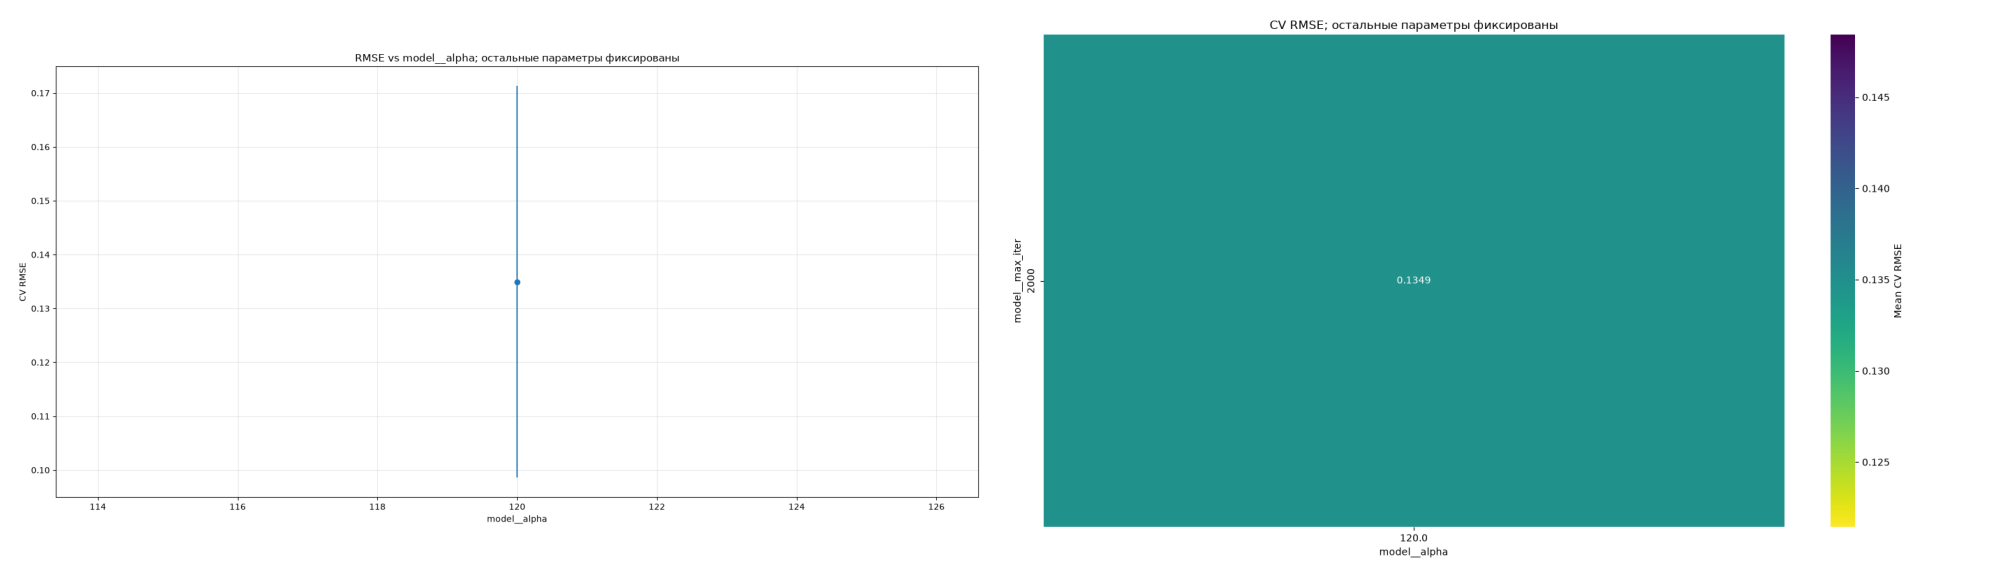

In [104]:
# return {
#     "run_id": run_id,
#     "results_df": results_df,
#     "best_value": oof_rmse,
#     "best_ensemble": pipelines,
#     "for_shap": for_shap,
#     "best_results": best_results,
#     'best_history": best_history,
#     'cv_folds':cv_folds
#     }

ridge_results = run_experiment(
    X_train, y_train,
    "ridge",
    ridge_pipeline,
    logger
)

### Второй этап, подбор лучших гиперпараметров Optuna

In [ ]:
def suggest_ridge_params(trial):
    return {
        "model__alpha": trial.suggest_float(
            "model__alpha",
            0.001,
            20,
            log=True,
        ),
        "model__max_iter": trial.suggest_int(
            "model__max_iter",
            100,
            1000,
        ),
    }

ridge_optuna_pipeline = {"ridge_optuna": {
        "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", Ridge()),
            ]),
        "parameters_to_search": suggest_ridge_params,
        "search_type": "grid",
        "fit_param": {
            "model__solver": "saga",
            "model__random_state": Config.seed
        },
        "n_iter": 100,
        "plot_param": "model__alpha",
        "heatmap_params": ("model__alpha", "model__max_iter"),
        "shap_mode":"linear",
        "cv": 5,
        "n_jobs":-1}}

In [ ]:
# return {
#     "run_id": model_run_id,
#     "results_df": results_df,
#     "best_value": best_value,
#     "best_ensemble": best_ensemble,
#     "best_results": best_results,
#     "best_history": best_history,
#     "figures": double_fig
# }

ridge_optuna_results = run_optuna_experiment(
    X_train,
    y_train,
    "ridge_optuna",
    ridge_optuna_pipeline,
    logger
)

### Третий этап, подсчет SHAP признаков и отбор признаков

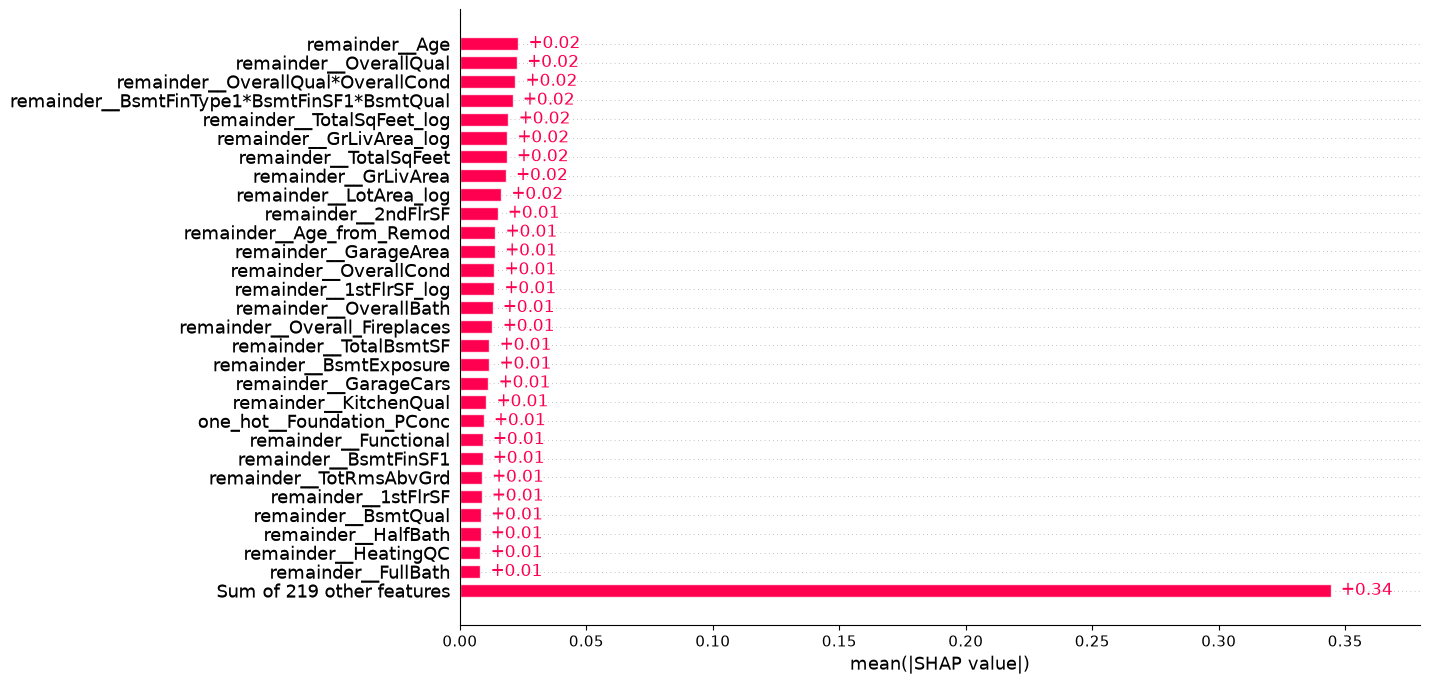

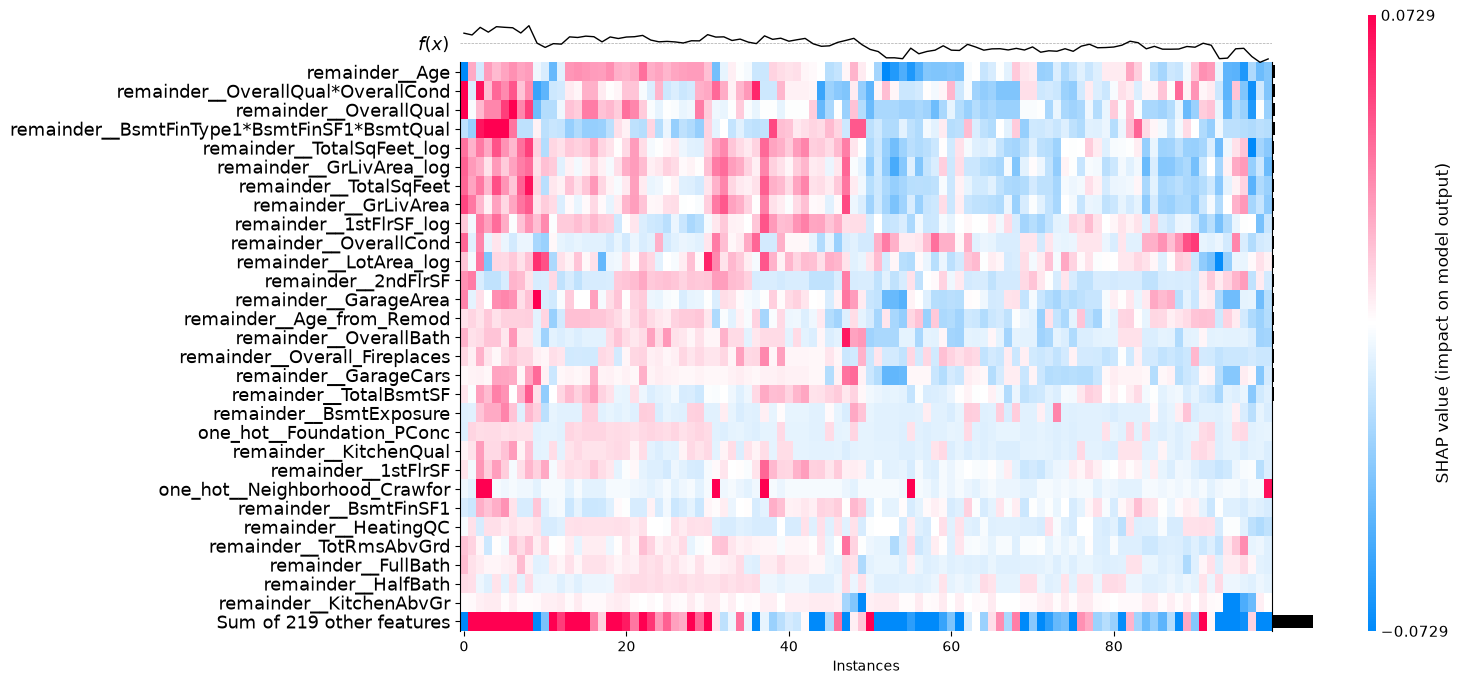

In [105]:
# return {
#     "importance": importance,
#     "oof_explanation": oof_explanation,
#     "figures": figures
# }

ridge_shap = run_shap(
    X_train,
    ridge_results,
    mode="linear",
    logger = logger
)

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF: 0.1385984323568962, best mean val RMSE: 0.1335117926486925, best val std: 0.03699354976926007, best feature amount: 57
-----Best searched params-----
model__alpha         120.0
model__max_iter       2000
model__random_state     42
model__solver          svd


,params,off_score,mean_val_score,std_val_score,feature_count,split0_val_score,split1_val_score,split2_val_score,split3_val_score,split4_val_score,param_model__alpha,param_model__max_iter,param_model__random_state,param_model__solver,candidate_id
3,"{'model__alpha': 120.0, 'model__max_iter': 200...",0.138598,0.133512,0.036994,191,0.123294,0.144145,0.199569,0.105385,0.095166,120.0,2000,42,svd,3
6,"{'model__alpha': 120.0, 'model__max_iter': 200...",0.138882,0.133198,0.039116,141,0.121756,0.144277,0.203384,0.102365,0.094210,120.0,2000,42,svd,6
4,"{'model__alpha': 120.0, 'model__max_iter': 200...",0.138920,0.133596,0.037883,176,0.121858,0.144303,0.201636,0.105012,0.095169,120.0,2000,42,svd,4
5,"{'model__alpha': 120.0, 'model__max_iter': 200...",0.139286,0.133605,0.039162,155,0.121675,0.145587,0.203675,0.101175,0.095912,120.0,2000,42,svd,5
1,"{'model__alpha': 120.0, 'model__max_iter': 200...",0.139748,0.134521,0.037657,215,0.122968,0.142841,0.203008,0.107718,0.096069,120.0,2000,42,svd,1
2,"{'model__alpha': 120.0, 'model__max_iter': 200...",0.139860,0.134652,0.037602,207,0.122972,0.143448,0.202888,0.107641,0.096313,120.0,2000,42,svd,2
0,"{'model__alpha': 120.0, 'model__max_iter': 200...",0.140673,0.135416,0.037892,229,0.122935,0.143030,0.204793,0.109122,0.097200,120.0,2000,42,svd,0
7,"{'model__alpha': 120.0, 'model__max_iter': 200...",0.143503,0.137335,0.041414,114,0.120462,0.148438,0.212993,0.103210,0.101570,120.0,2000,42,svd,7
8,"{'model__alpha': 120.0, 'model__max_iter': 200...",0.149444,0.143295,0.042209,94,0.125389,0.154955,0.220368,0.109086,0.106678,120.0,2000,42,svd,8


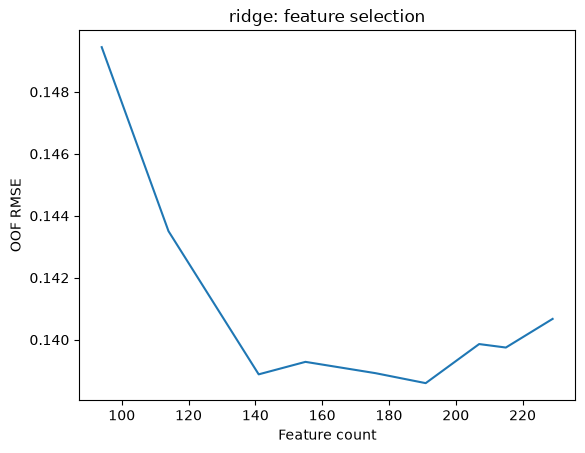

In [106]:
# return {
#     "results_df": results_df,
#     "best_ensemble": best_ensemble,
#     "best_oof_score": best_oof_score,
#     "best_results": fs_best_results,
#     "best_history": best_history,
#     "figures": fig
# }

ridge_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=ridge_results['cv_folds'],
    importance=ridge_shap['importance'],
    search_results=ridge_results['best_results'],
    model_name="ridge",
    model_configs=ridge_pipeline,
    model_run_id=ridge_results['run_id'],
    logger=logger
)

if ridge_fs_results["best_oof_score"] < ridge_results['best_results']['best_oof_score']:
    ModelSaver.save_ensemble(ridge_fs_results['best_ensemble'],"ridge", save_fs=ridge_fs_results['best_results']['best_cols'])
else:
    ModelSaver.save_ensemble(ridge_results['best_ensemble'],"ridge")

## Lasso

In [61]:
lasso_pipeline = {"lasso": {
        "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", Lasso()),
            ]),
        "parameters": {
            "model__alpha": [0.0036868686868686868],  # np.float64(0.11144234247204798)
            "model__max_iter": [100],
            "model__random_state": [Config.seed],
        },
        "search_type": "grid",
        "fit_param": {},
        "n_iter": 1,
        "plot_param": "model__alpha",
        "heatmap_params": ("model__alpha", "model__max_iter"),
        "shap_mode":"linear",
        "cv": 5,
        "n_jobs":-1}}

Начинаем обучение 1 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF 0.14301004925824556, best mean val RMSE 0.1354643318395064, best_val_std 0.04563233288627216
Best searched params
model__alpha           0.003687
model__max_iter      100.000000
model__random_state   42.000000


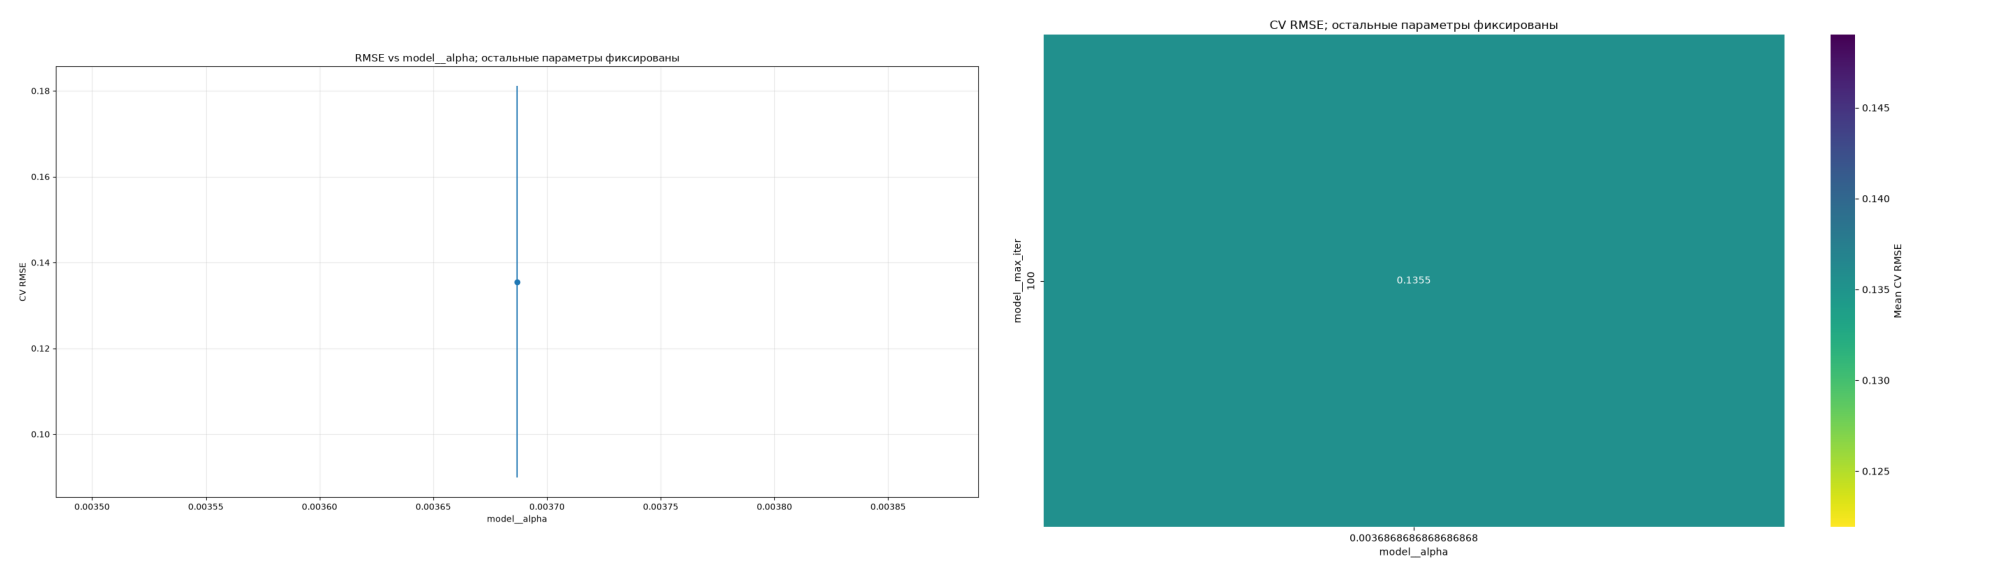

In [62]:
lasso_results = run_experiment(
    X_train, y_train,
    "lasso",
    lasso_pipeline,
    logger
)

ModelSaver.save_ensemble(lasso_results['best_ensemble'],"lasso")

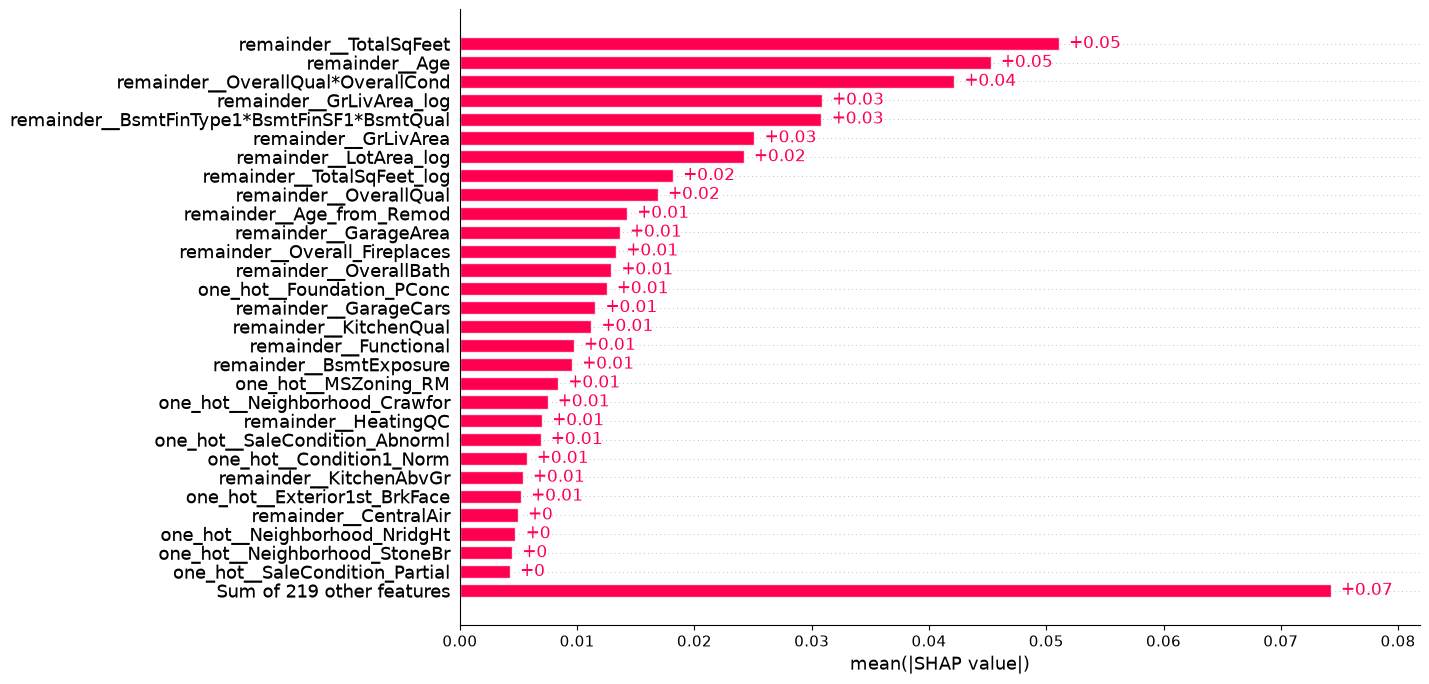

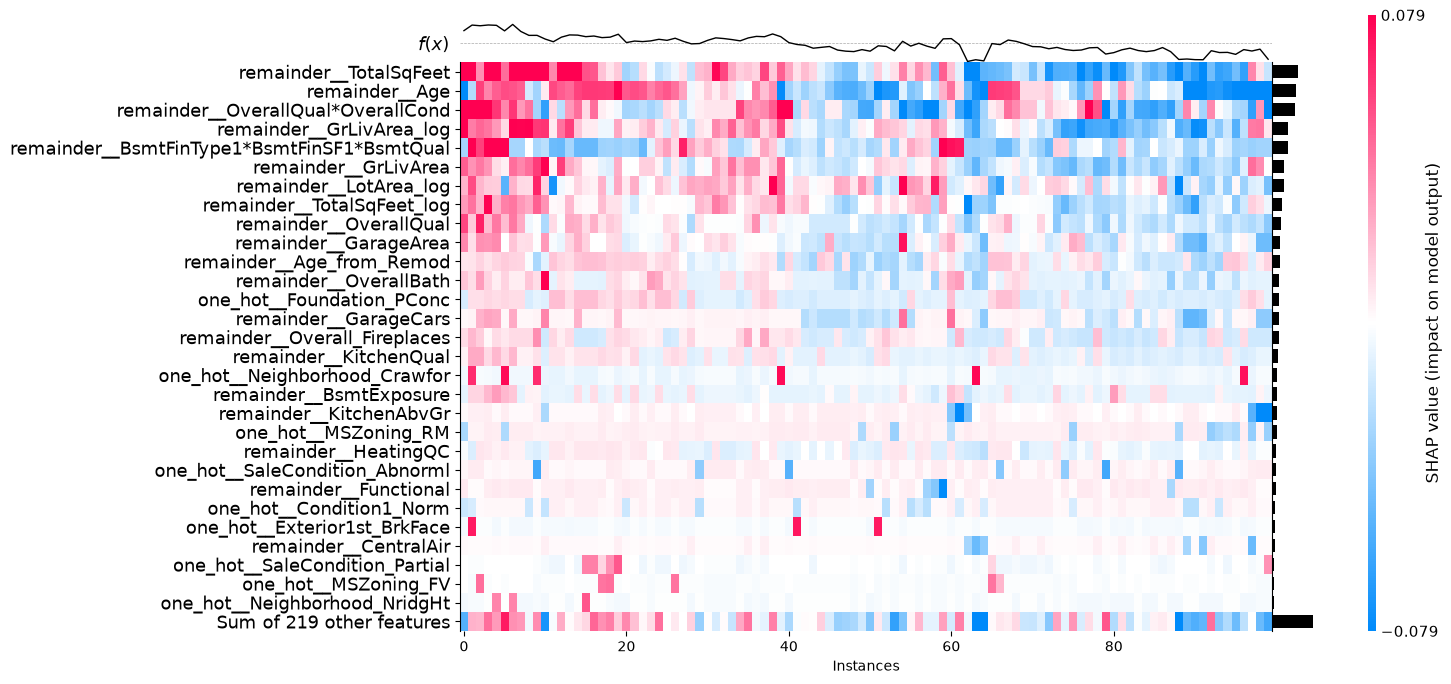

In [63]:
lasso_shap = run_shap(
    X_train,
    lasso_results,
    mode="linear",
    logger = logger
)

## DNN

In [107]:
dnn_pipeline = {"dnn": {
                "pipeline": Pipeline([
                    ("feature_transform", FeatureTransformer()),
                    ("encoder", DNN_encoder()),
                    ("model", MyModel()),
                ]),

                "parameters": {
                    # Данные
                    "model__cat_cols": [FeatureTransformer.cat_cols],
                    "model__num_cols": [FeatureTransformer.num_cols],
                    # Обучение
                    "model__epochs": [1000],
                    "model__device": [Config.device],
                    # Архитектура
                    "model__emb_dim": [12],
                    "model__inner_n": [512],
                    "model__drop_n": [0.1],
                    "model__n_layers": [1],
                    "model__use_batchnorm": [True],
                    # Loss
                    "model__loss_reg": [RMSELoss],
                    #Regularization
                    "model__l1_lambda":[0.003433628682365358],
                    # Optimizer
                    "model__optim": [torch.optim.Adam],
                    "model__optim_lr": [0.08686979995821902],
                    # Scheduler
                    "model__scheduler": [
                        torch.optim.lr_scheduler.ReduceLROnPlateau
                    ],
                    "model__lr_scheduler": [True],
                    "model__factor": [0.08066252499544253],
                    "model__patience": [15],
                    "model__threshold": [0.01],
                    "model__min_lr": [1e-10],
                    # Early Stopping
                    "model__early_stopping_patience": [45],
                    "model__early_stopping_threshold": [0.001],
                    # DataLoader
                    "model__batch_size": [64],
                    # Checkpoint
                    "model__saving_threshold": [0.001],
                    "model__save_path": ["checkpoints"],
                },
                "search_type": "grid",
                "fit_param": {"model__callbacks":[CheckpointManager(),EarlyStopping()]}, #,MLflow_logger()
                "n_iter": 1, #для рандом серча
                "plot_param": "model__optim_lr",
                "heatmap_params": ("model__optim_lr", "model__n_layers"),
                "shap_mode": "dnn",
                "cv": 5,
                "n_jobs": 1,
        }
}

Начинаем обучение 1 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Обучение остановлено на эпохе 170


Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Обучение остановлено на эпохе 108


... (2 outputs left out)

Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Обучение остановлено на эпохе 150


Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Обучение остановлено на эпохе 170
Best OOF 0.1366921621001253, best mean val RMSE 0.13183871423653018, best_val_std 0.035900506360053715
Best searched params
model__batch_size                                                                  64
model__device                                                                     cpu
model__drop_n                                                                     0.1
model__early_stopping_patience                                                     45
model__early_stopping_threshold                                                 0.001
model__emb_dim                                                                     12
model__epochs                                                                    1000
model__factor                                                                0.080663
model__inner_n                                                                    512
model__l1_lambda                                                    

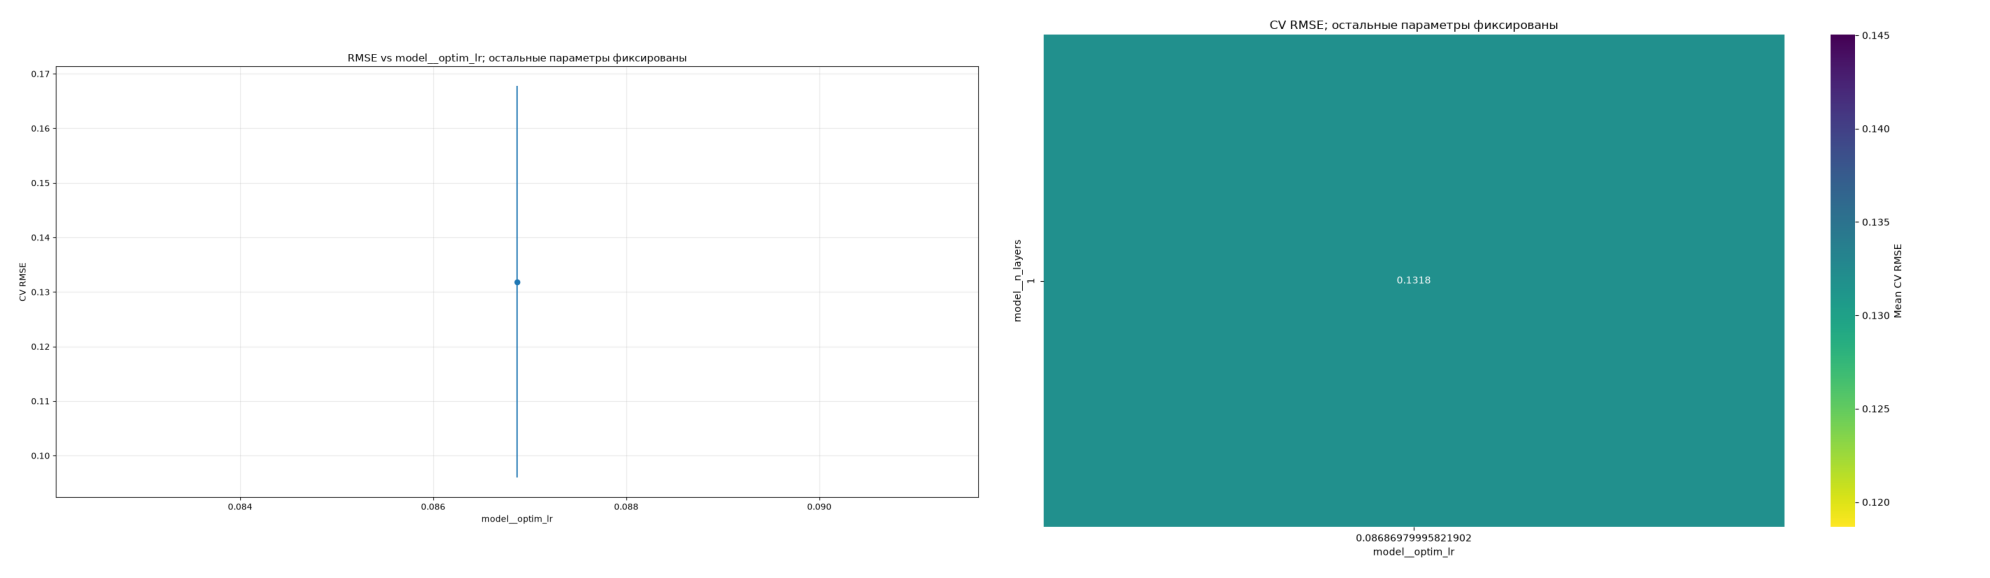

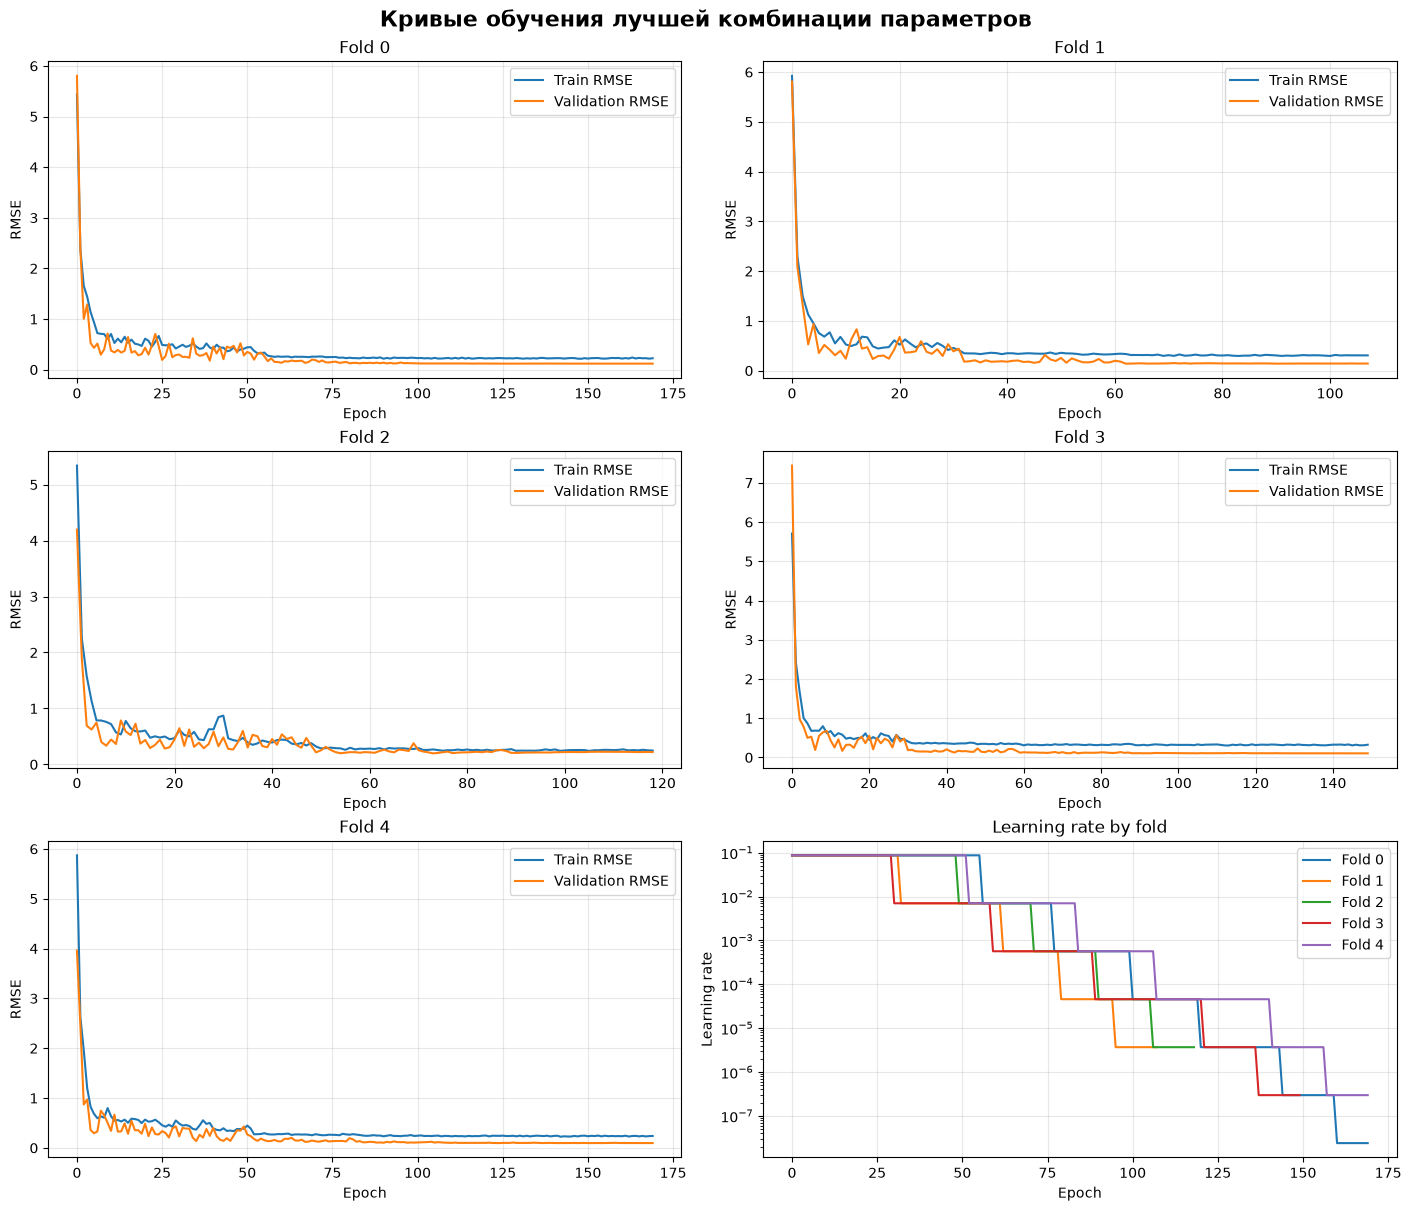

In [65]:
# return {
#     "run_id": run_id,
#     "results_df": results_df,
#     "oof_rmse": oof_rmse,
#     "best_results": best_results,
#     "for_shap": for_shap,
#     "best_history": best_history,
#     "figures": figures
# }

dnn_results = run_experiment(
    X_train, y_train,
    "dnn",
    dnn_pipeline,
    logger
)

### Optuna

In [ ]:
def suggest_dnn_params(trial):
    return {
        "model__emb_dim": trial.suggest_categorical(
            "model__emb_dim",
            [12,24]
        ),
        "model__drop_n": trial.suggest_categorical(
            "model__drop_n",
            [0.1,0.2]
        ),
        "model__n_layers": trial.suggest_categorical(
            "model__n_layers",
            [1,2,3,4]
        ),
        'model__inner_n': trial.suggest_categorical(
            "model__inner_n",
            [64,128,256,512]
        ),
        "model__use_batchnorm": trial.suggest_categorical(
            "model__use_batchnorm",
            [True,False]
        ),
        "model__l1_lambda": trial.suggest_float(
            "model__l1_lambda",
            0.001,
            20,
            log=True,
        ),
        "model__optim_lr": trial.suggest_float(
            "model__optim_lr",
            0.00001,
            0.1
        ),
        "model__use_batchnorm": trial.suggest_categorical(
            "model__use_batchnorm", 
            [True, False]),
            # Scheduler
        "model__factor": trial.suggest_float(
            "model__factor", 
            0.01,
            0.1
        ),
        "model__patience": trial.suggest_categorical(
            "model__patience", [5,10,15,20]
        ),
        "model__threshold": trial.suggest_categorical(
            "model__threshold", [0.001,0.01,0.1]
        ),
        "model__min_lr": trial.suggest_categorical(
            "model__min_lr", [1e-10]
        ),
        # Early Stopping
        "model__early_stopping_patience": trial.suggest_categorical(
            "model__early_stopping_patience", [20,30,35,45]
        ),
        "model__early_stopping_threshold": trial.suggest_categorical(
            "model__early_stopping_threshold", [0.01, 0.001,0.0001]
        ),
        # DataLoader
        "model__batch_size": trial.suggest_categorical(
            "model__batch_size", [64,128,256,512]
        ),
        # Checkpoint
        "model__saving_threshold": trial.suggest_categorical(
            "model__saving_threshold", [0.001]
        ),
    }

dnn_optuna_pipeline = {"dnn_optuna": {
                "pipeline": Pipeline([
                    ("feature_transform", FeatureTransformer()),
                    ("encoder", DNN_encoder()),
                    ("model", MyModel()),
                ]),

            "parameters_to_search": suggest_dnn_params,
            "search_type": "grid",
            "fit_param": {
                "model__solver": "saga",
                "model__random_state": Config.seed
            },
            "search_type": "grid",
            "fit_param": {"model__callbacks":[CheckpointManager(),EarlyStopping()],
                          "model__device": Config.device,
                          "model__cat_cols": FeatureTransformer.cat_cols,
                          "model__num_cols": FeatureTransformer.num_cols,
                          "model__loss_reg": RMSELoss, #Сделать RMSE losss
                          "model__epochs": 1000,
                          "model__optim": torch.optim.Adam,
                          "model__scheduler":torch.optim.lr_scheduler.ReduceLROnPlateau,
                          "model__lr_scheduler": True,
                          
                          },
            "n_iter": 1, #для оптуны
            "plot_param": "model__optim_lr",
            "heatmap_params": ("model__inner_n", "model__n_layers"),
            "shap_mode": "dnn",
            "cv": 5,
            "n_jobs": -1,
            }}

In [ ]:
# return {
#     "run_id": model_run_id,
#     "results_df": results_df,
#     "best_value": best_value,
#     "best_ensemble": best_ensemble,
#     "best_results": best_results,
#     "best_history": best_history,
#     "figures": double_fig
# }
#Добавить функцию сохраненния обученного пайплайна

dnn_optuna_results = run_optuna_experiment(
    X_train,
    y_train,
    "dnn_optuna",
    dnn_optuna_pipeline,
    logger
)

### SHAP и отбор признаков

PermutationExplainer explainer: 235it [00:17,  6.00it/s]                         
PermutationExplainer explainer: 235it [00:21,  5.85it/s]                         
PermutationExplainer explainer: 235it [00:15,  5.32it/s]                         
PermutationExplainer explainer: 234it [00:15,  5.32it/s]                         
PermutationExplainer explainer: 234it [00:15,  5.25it/s]                         


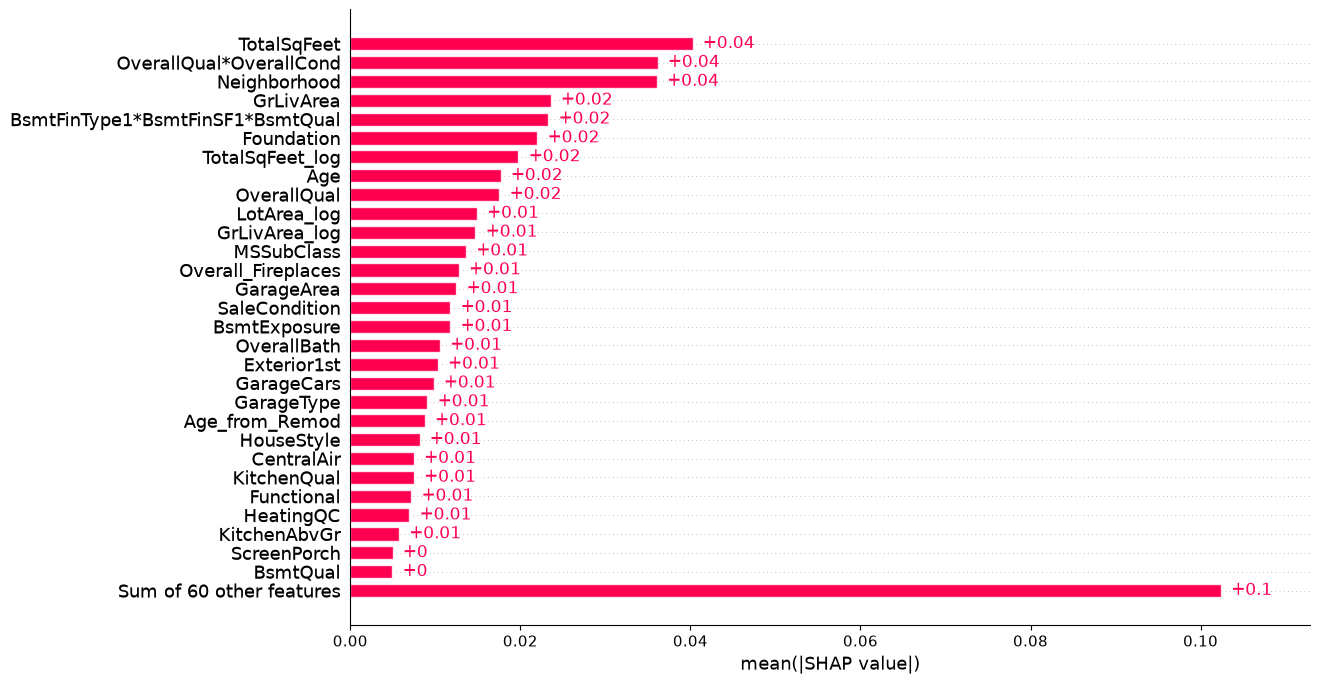

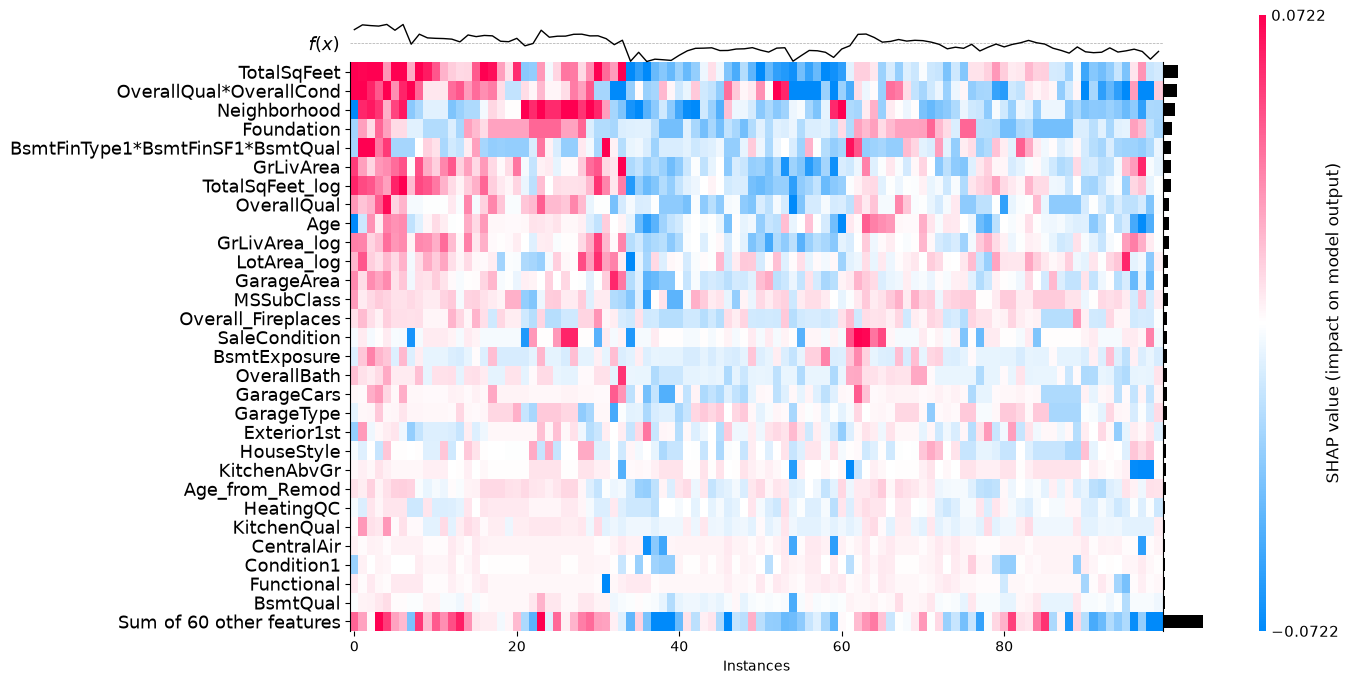

In [66]:
# return {
#     "importance": importance,
#     "oof_explanation": oof_explanation,
#     "figures": figures
# }

dnn_optuna_shap = run_shap(
    X_train,
    dnn_results,
    mode="dnn",
    logger = logger
)

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Обучение остановлено на эпохе 159


Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Обучение остановлено на эпохе 122


Training:   0%|          | 0/1000 [00:00<?, ?it/s]

... (90 outputs left out)

Обучение остановлено на эпохе 180


Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Обучение остановлено на эпохе 110
Best OOF: 0.13233944304013712, best mean val RMSE: 0.12752797565663537, best val std: 0.03516147701461553, best feature amount: 57
-----Best searched params-----
model__batch_size                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                   

,params,off_score,mean_val_score,std_val_score,feature_count,split0_val_score,split1_val_score,split2_val_score,split3_val_score,split4_val_score,...,param_model__num_cols,param_model__optim,param_model__optim_lr,param_model__patience,param_model__save_path,param_model__saving_threshold,param_model__scheduler,param_model__threshold,param_model__use_batchnorm,candidate_id
3,"{'model__batch_size': 64, 'model__cat_cols': [...",0.132339,0.127528,0.035161,57,0.115881,0.138952,0.190084,0.101823,0.090901,...,"[GrLivArea, GrLivArea_log, FullBath, TotRmsAbv...",<class 'torch.optim.adam.Adam'>,0.08687,15,checkpoints,0.001,<class 'torch.optim.lr_scheduler.ReduceLROnPla...,0.01,True,3
1,"{'model__batch_size': 64, 'model__cat_cols': [...",0.133856,0.129125,0.035073,73,0.116354,0.139227,0.192553,0.101616,0.095876,...,"[GrLivArea, GrLivArea_log, FullBath, TotRmsAbv...",<class 'torch.optim.adam.Adam'>,0.08687,15,checkpoints,0.001,<class 'torch.optim.lr_scheduler.ReduceLROnPla...,0.01,True,1
7,"{'model__batch_size': 64, 'model__cat_cols': [...",0.134524,0.129862,0.034901,25,0.120012,0.140790,0.191977,0.101345,0.095186,...,"[GrLivArea, GrLivArea_log, FullBath, TotRmsAbv...",<class 'torch.optim.adam.Adam'>,0.08687,15,checkpoints,0.001,<class 'torch.optim.lr_scheduler.ReduceLROnPla...,0.01,True,7
4,"{'model__batch_size': 64, 'model__cat_cols': [...",0.134644,0.129320,0.037292,49,0.118819,0.134371,0.197920,0.105424,0.090067,...,"[GrLivArea, GrLivArea_log, FullBath, TotRmsAbv...",<class 'torch.optim.adam.Adam'>,0.08687,15,checkpoints,0.001,<class 'torch.optim.lr_scheduler.ReduceLROnPla...,0.01,True,4
2,"{'model__batch_size': 64, 'model__cat_cols': [...",0.135587,0.130296,0.037312,65,0.117154,0.136541,0.199418,0.103387,0.094982,...,"[GrLivArea, GrLivArea_log, FullBath, TotRmsAbv...",<class 'torch.optim.adam.Adam'>,0.08687,15,checkpoints,0.001,<class 'torch.optim.lr_scheduler.ReduceLROnPla...,0.01,True,2
0,"{'model__batch_size': 64, 'model__cat_cols': [...",0.135675,0.130346,0.037456,81,0.118069,0.136905,0.199549,0.101487,0.095719,...,"[GrLivArea, GrLivArea_log, FullBath, TotRmsAbv...",<class 'torch.optim.adam.Adam'>,0.08687,15,checkpoints,0.001,<class 'torch.optim.lr_scheduler.ReduceLROnPla...,0.01,True,0
6,"{'model__batch_size': 64, 'model__cat_cols': [...",0.136491,0.130463,0.039913,33,0.117754,0.140636,0.202875,0.098274,0.092775,...,"[GrLivArea, GrLivArea_log, FullBath, TotRmsAbv...",<class 'torch.optim.adam.Adam'>,0.08687,15,checkpoints,0.001,<class 'torch.optim.lr_scheduler.ReduceLROnPla...,0.01,True,6
5,"{'model__batch_size': 64, 'model__cat_cols': [...",0.136689,0.131147,0.038329,41,0.118775,0.138952,0.201220,0.104554,0.092234,...,"[GrLivArea, GrLivArea_log, FullBath, TotRmsAbv...",<class 'torch.optim.adam.Adam'>,0.08687,15,checkpoints,0.001,<class 'torch.optim.lr_scheduler.ReduceLROnPla...,0.01,True,5
8,"{'model__batch_size': 64, 'model__cat_cols': [...",0.139034,0.134460,0.035164,17,0.121042,0.144389,0.198315,0.105730,0.102823,...,"[GrLivArea, GrLivArea_log, FullBath, TotRmsAbv...",<class 'torch.optim.adam.Adam'>,0.08687,15,checkpoints,0.001,<class 'torch.optim.lr_scheduler.ReduceLROnPla...,0.01,True,8


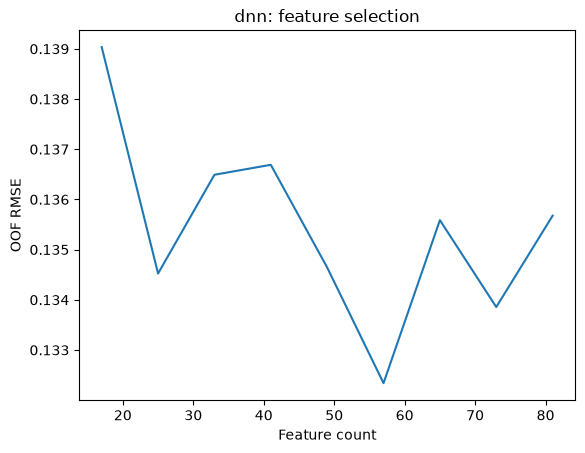

In [108]:
dnn_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=dnn_results['cv_folds'],
    importance=dnn_optuna_shap['importance'],
    search_results=dnn_results['best_results'],
    model_name="dnn",
    model_configs=dnn_pipeline,
    model_run_id=dnn_results['run_id'],
    logger=logger
)

if dnn_fs_results["best_oof_score"] < dnn_results['best_results']['best_oof_score']:
    ModelSaver.save_ensemble(dnn_fs_results['best_ensemble'],"DNN", save_fs=dnn_fs_results['best_results']['best_cols'])
else:
    ModelSaver.save_ensemble(dnn_results['best_ensemble'],"DNN")

## Catboost

In [109]:
catboost_pipeline = {"catboost": {
        "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer(cat_boosting=True)),
            ("model", CatBoostRegressor(allow_writing_files=False)),
        ]),
        "parameters": {
            "model__boosting_type": ["Plain"],  # ["Plain", "Ordered"]
            "model__iterations": [1000],  # np.linspace(1, 100, 5, dtype=int)
            "model__learning_rate": [0.05211448378065621],  # [0.08]
            "model__depth": [4],  # [4, 5, 6, 8]
            "model__bootstrap_type": ["Bernoulli"],
            "model__thread_count": [-1],
            "model__l2_leaf_reg": [0.01727277227745447],  # np.float64(0.0098)
            "model__rsm": [1.0],  # [0.6, 0.8, 1.0]
            "model__subsample": [0.8],
            "model__border_count": [256],
            "model__min_data_in_leaf": [50],
            "model__max_ctr_complexity": [2],
            "model__one_hot_max_size": [6],
            "model__eval_metric": ["RMSE"],
            "model__loss_function": ["RMSE"],
            "model__random_strength": [1.7444045228543141],  # [0, 0.5, 1, 2]
            "model__verbose": [False],
            "model__random_seed": [Config.seed],
            'model__early_stopping_rounds':[50]
        },
        'fit_param': {"model__cat_features": FeatureTransformer.cat_cols},
        "n_iter": 1,
        "plot_param": "model__learning_rate",
        "heatmap_params": ("model__learning_rate", "model__l2_leaf_reg"),
        "shap_mode": "catboost",
        "cv": 5,
        "n_jobs": - 1,
    }
}

Начинаем обучение 1 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF 0.12267528808321224, best mean val RMSE 0.12140910630861128, best_val_std 0.017356852980154512
Best searched params
model__boosting_type              Plain
model__bootstrap_type         Bernoulli
model__border_count                 256
model__depth                          4
model__early_stopping_rounds         50
model__eval_metric                 RMSE
model__iterations                  1000
model__l2_leaf_reg             0.017273
model__learning_rate           0.052114
model__loss_function               RMSE
model__max_ctr_complexity             2
model__min_data_in_leaf              50
model__one_hot_max_size               6
model__random_seed                   42
model__random_strength         1.744405
model__rsm                          1.0
model__subsample                    0.8
model__thread_count                  -1
model__verbose                    False


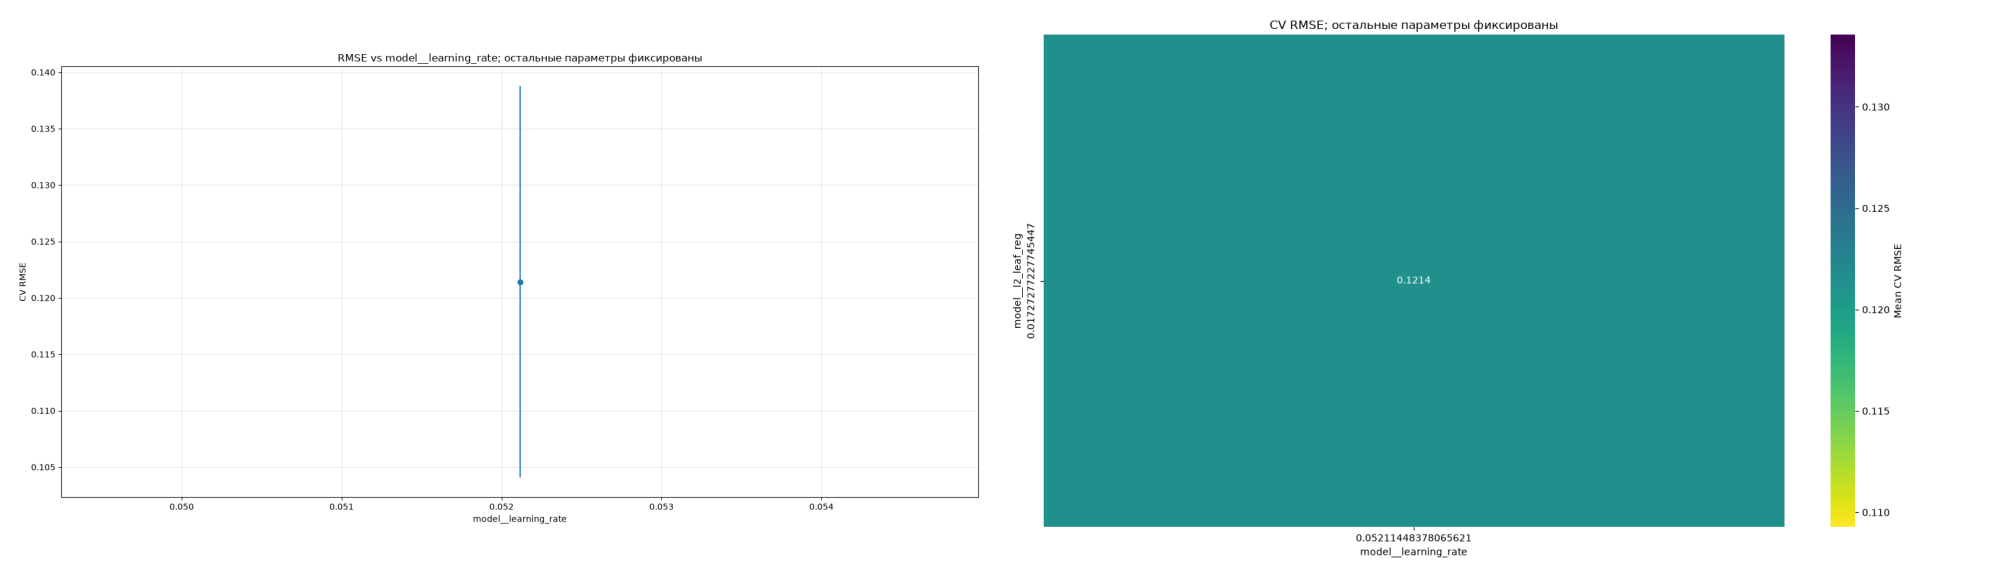

In [110]:
catboost_results = run_experiment(
    X_train, y_train,
    "catboost",
    catboost_pipeline,
    logger
)
ModelSaver.save_ensemble(catboost_results['best_ensemble'],"catboost")

### Optuna

In [ ]:
def suggest_catboost_params(trial):
    return {
        "model__boosting_type": trial.suggest_categorical(
            "model__boosting_type", ["Plain"]
        ),
        "model__iterations": trial.suggest_categorical(
            "model__iterations", [1000]
        ),
        "model__learning_rate": trial.suggest_float(
            "model__learning_rate",
            0.001,
            0.10,
            log=True,
        ),
        "model__depth": trial.suggest_categorical(
            "model__depth", [4, 5, 6, 8]
        ),
        "model__l2_leaf_reg":trial.suggest_float(
            "model__l2_leaf_reg",
            0.001,
            0.10,
            log=True,
        ),
        "model__subsample": trial.suggest_categorical(
            "model__subsample", [0.6,0.8,0.1]
        ),
        "model__border_count": trial.suggest_categorical(
            "model__border_count", [32,64,128,256]
        ),
        "model__min_data_in_leaf": trial.suggest_categorical(
            "model__min_data_in_leaf", [30,35,45,50]
        ),
        "model__max_ctr_complexity": trial.suggest_categorical(
            "model__max_ctr_complexity", [1,2,3,4]
        ),
        "model__one_hot_max_size": trial.suggest_categorical(
            "model__one_hot_max_size", [4,5,6]
        ),
        "model__random_strength": trial.suggest_float(
            'model__random_strength', 
            1e-3, 
            10.0, 
            log=True
        ),
        'model__early_stopping_rounds':trial.suggest_categorical(
            "model__early_stopping_rounds", [25,35,50]
        )
    }

catboost_optuna_pipeline = {
    "catboost_optuna": {
        "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer(cat_boosting=True)),
            ("model", CatBoostRegressor(allow_writing_files=False)),
        ]),
            "parameters_to_search": suggest_catboost_params,
            "search_type": "grid",
            "fit_param": {"model__random_seed": Config.seed,
                          "model__cat_features": FeatureTransformer.cat_cols,
                          "model__thread_count": -1,
                          "model__rsm": 1.0,
                          "model__bootstrap_type": "Bernoulli",
                          "model__eval_metric": "RMSE",
                          "model__loss_function": "RMSE",
                          "model__verbose": False,
                          },
            "n_iter": 500, #для оптуны
            "plot_param": "model__learning_rate",
            "heatmap_params": ("model__learning_rate", "model__l2_leaf_reg"),
            "shap_mode": "catboost",
            "cv": 5,
            "n_jobs": 1,
            }
        }

In [ ]:
catboost_optuna_results = run_optuna_experiment(
    X_train,
    y_train,
    "catboost_optuna",
    catboost_optuna_pipeline,
    logger
)

### SHAP и отбор признаков

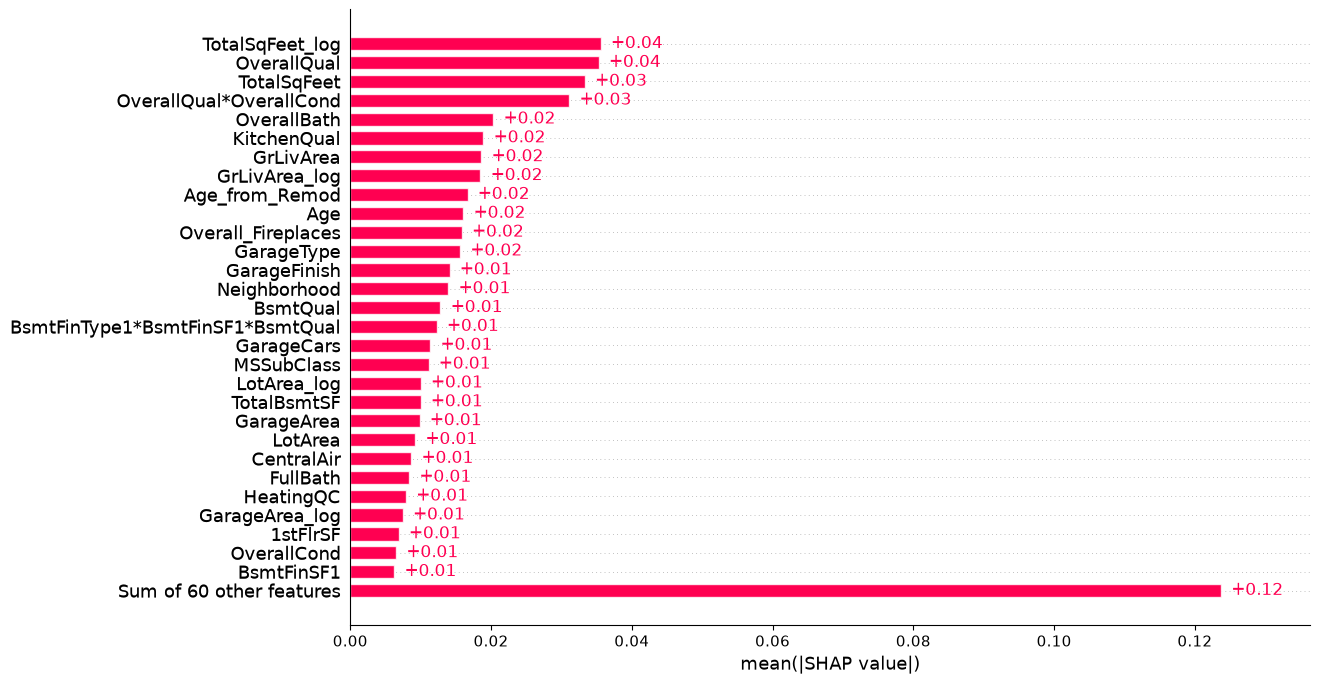

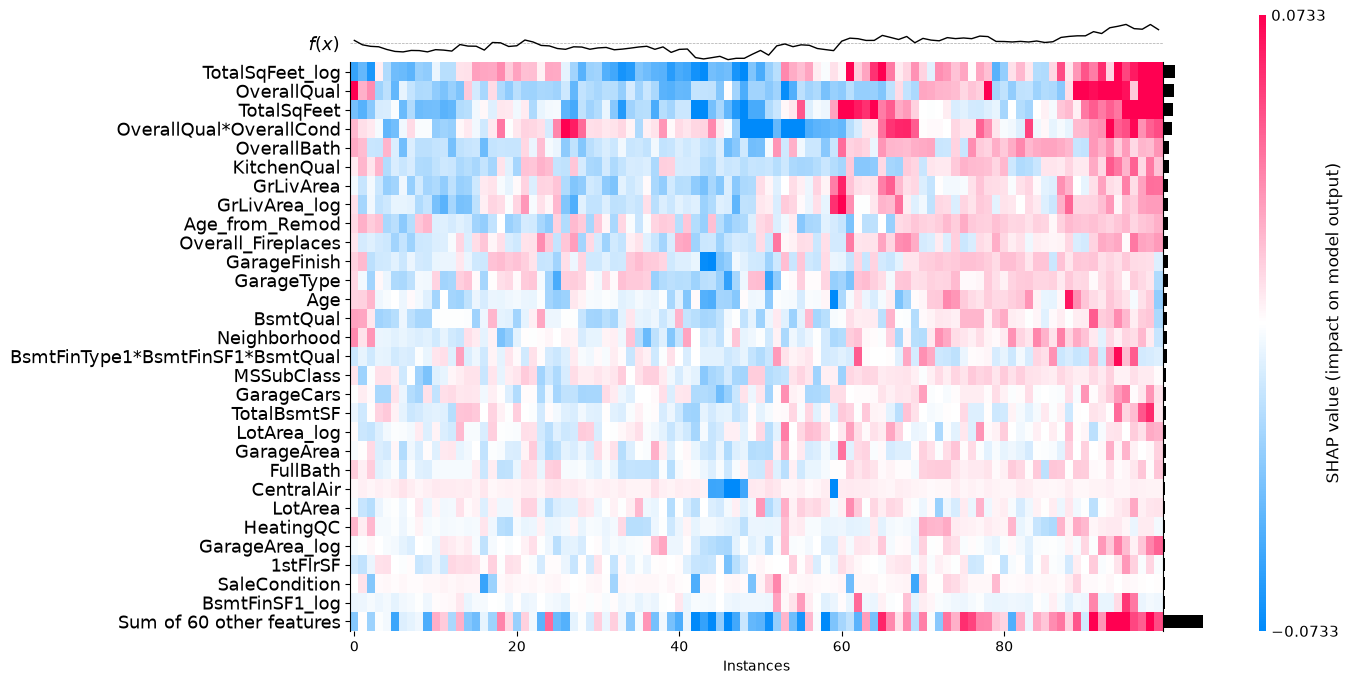

In [70]:
catboost_shap = run_shap(
    X_train,
    catboost_results,
    mode="catboost",
    logger = logger
)

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF: 0.12287658782035721, best mean val RMSE: 0.12159199763358845, best val std: 0.01749552367862457, best feature amount: 33
-----Best searched params-----
model__boosting_type              Plain
model__bootstrap_type         Bernoulli
model__border_count                 256
model__depth                          4
model__early_stopping_rounds         50
model__eval_metric                 RMSE
model__iterations                  1000
model__l2_leaf_reg             0.017273
model__learning_rate           0.052114
model__loss_function               RMSE
model__max_ctr_complexity             2
model__min_data_in_leaf              50
model__one_hot_max_size               6
model__random_seed                   42
model__random_strength         1.744405
model__rsm                          1.0
model__subsample                    0.8
model__thread_count                  -1
model__verbose                    False


,params,off_score,mean_val_score,std_val_score,feature_count,split0_val_score,split1_val_score,split2_val_score,split3_val_score,split4_val_score,...,param_model__max_ctr_complexity,param_model__min_data_in_leaf,param_model__one_hot_max_size,param_model__random_seed,param_model__random_strength,param_model__rsm,param_model__subsample,param_model__thread_count,param_model__verbose,candidate_id
6,"{'model__boosting_type': 'Plain', 'model__boot...",0.122877,0.121592,0.017496,33,0.123402,0.133824,0.146353,0.104603,0.099778,...,2,50,6,42,1.744405,1.0,0.8,-1,False,6
0,"{'model__boosting_type': 'Plain', 'model__boot...",0.122912,0.121138,0.020588,81,0.122504,0.131874,0.153045,0.101930,0.096337,...,2,50,6,42,1.744405,1.0,0.8,-1,False,0
1,"{'model__boosting_type': 'Plain', 'model__boot...",0.123517,0.122100,0.018430,73,0.123895,0.137102,0.146227,0.106665,0.096610,...,2,50,6,42,1.744405,1.0,0.8,-1,False,1
3,"{'model__boosting_type': 'Plain', 'model__boot...",0.124191,0.122593,0.019635,57,0.123280,0.134523,0.152226,0.104140,0.098797,...,2,50,6,42,1.744405,1.0,0.8,-1,False,3
2,"{'model__boosting_type': 'Plain', 'model__boot...",0.124283,0.122448,0.021058,65,0.122743,0.136689,0.153523,0.101699,0.097584,...,2,50,6,42,1.744405,1.0,0.8,-1,False,2
4,"{'model__boosting_type': 'Plain', 'model__boot...",0.124965,0.123104,0.021268,49,0.121651,0.136968,0.155288,0.105114,0.096499,...,2,50,6,42,1.744405,1.0,0.8,-1,False,4
5,"{'model__boosting_type': 'Plain', 'model__boot...",0.125061,0.123290,0.020748,41,0.123261,0.137725,0.153836,0.101410,0.100217,...,2,50,6,42,1.744405,1.0,0.8,-1,False,5
7,"{'model__boosting_type': 'Plain', 'model__boot...",0.125922,0.124850,0.016167,25,0.126140,0.136747,0.147456,0.109405,0.104500,...,2,50,6,42,1.744405,1.0,0.8,-1,False,7
8,"{'model__boosting_type': 'Plain', 'model__boot...",0.126951,0.125753,0.017159,17,0.129370,0.141786,0.145777,0.108561,0.103271,...,2,50,6,42,1.744405,1.0,0.8,-1,False,8


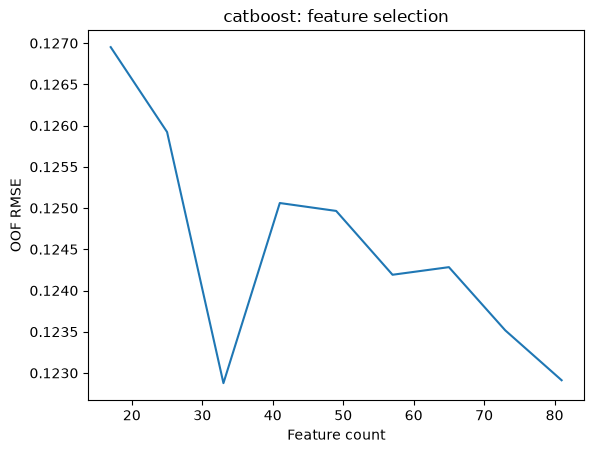

In [111]:
catboost_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=catboost_results['cv_folds'],
    importance=catboost_shap['importance'],
    search_results=catboost_results['best_results'],
    model_name="catboost",
    model_configs=catboost_pipeline,
    model_run_id=catboost_results['run_id'],
    logger=logger
)

if catboost_fs_results["best_oof_score"] < catboost_results['best_results']['best_oof_score']:
    ModelSaver.save_ensemble(catboost_fs_results['best_ensemble'],"catboost", save_fs=catboost_fs_results['best_results']['best_cols'])
else:
    ModelSaver.save_ensemble(catboost_results['best_ensemble'],"catboost")

## LightGBM

In [112]:
lightgbm_pipeline = {"lightgbm": {
        "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer(cat_boosting=True)),
            ("model", LGBMRegressor()),
        ]),
        "parameters": {
            "model__device": ["cpu"],
            "model__boosting_type": ["gbdt"],
            "model__n_estimators": [2000],  # np.linspace(1, 100, 5, dtype=int)
            "model__learning_rate": [0.098],  # np.linspace(0.01, 0.1, 5); [np.float64(0.0775)]
            "model__max_depth": [4],  # [4, 5, 6, 8]
            "model__subsample": [0.4],  # [0.6, 0.8, 1.0]
            "model__colsample_bytree": [0.8],  # [0.6, 0.8, 1.0]
            "model__reg_alpha": [0.008],  # [0.1, 0.2, 0.4, 0.5, 1]
            "model__reg_lambda": [0.04000000000000001],  # [0.01, 0.1, 0.5, 5, 10]
            "model__objective": ["regression"],
            "model__metric": ["rmse"],
            "model__min_child_samples": [40],
            "model__min_child_weight": [1],  # np.linspace(1, 5, 3, dtype=int)
            "model__min_split_gain": [0.0005],  # np.linspace(0.01, 0.1, 5)
            "model__n_jobs": [-1],
            "model__random_state": [Config.seed],
            "model__verbosity": [-1],
            "model__early_stopping_round":[30]
        },
        "fit_param" : {},
        "n_iter": 1,
        "plot_param": "model__learning_rate",
        "heatmap_params": ("model__learning_rate", "model__max_depth"),
        'shap_mode':'lightgbm',
        "cv": 5,
        "n_jobs": 1,
    }
}

Начинаем обучение 1 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mento

Best OOF 0.12635404894073082, best mean val RMSE 0.12499665340087314, best_val_std 0.018248109944472745
Best searched params
model__boosting_type               gbdt
model__colsample_bytree             0.8
model__device                       cpu
model__early_stopping_round          30
model__learning_rate              0.098
model__max_depth                      4
model__metric                      rmse
model__min_child_samples             40
model__min_child_weight               1
model__min_split_gain            0.0005
model__n_estimators                2000
model__n_jobs                        -1
model__objective             regression
model__random_state                  42
model__reg_alpha                  0.008
model__reg_lambda                  0.04
model__subsample                    0.4
model__verbosity                     -1


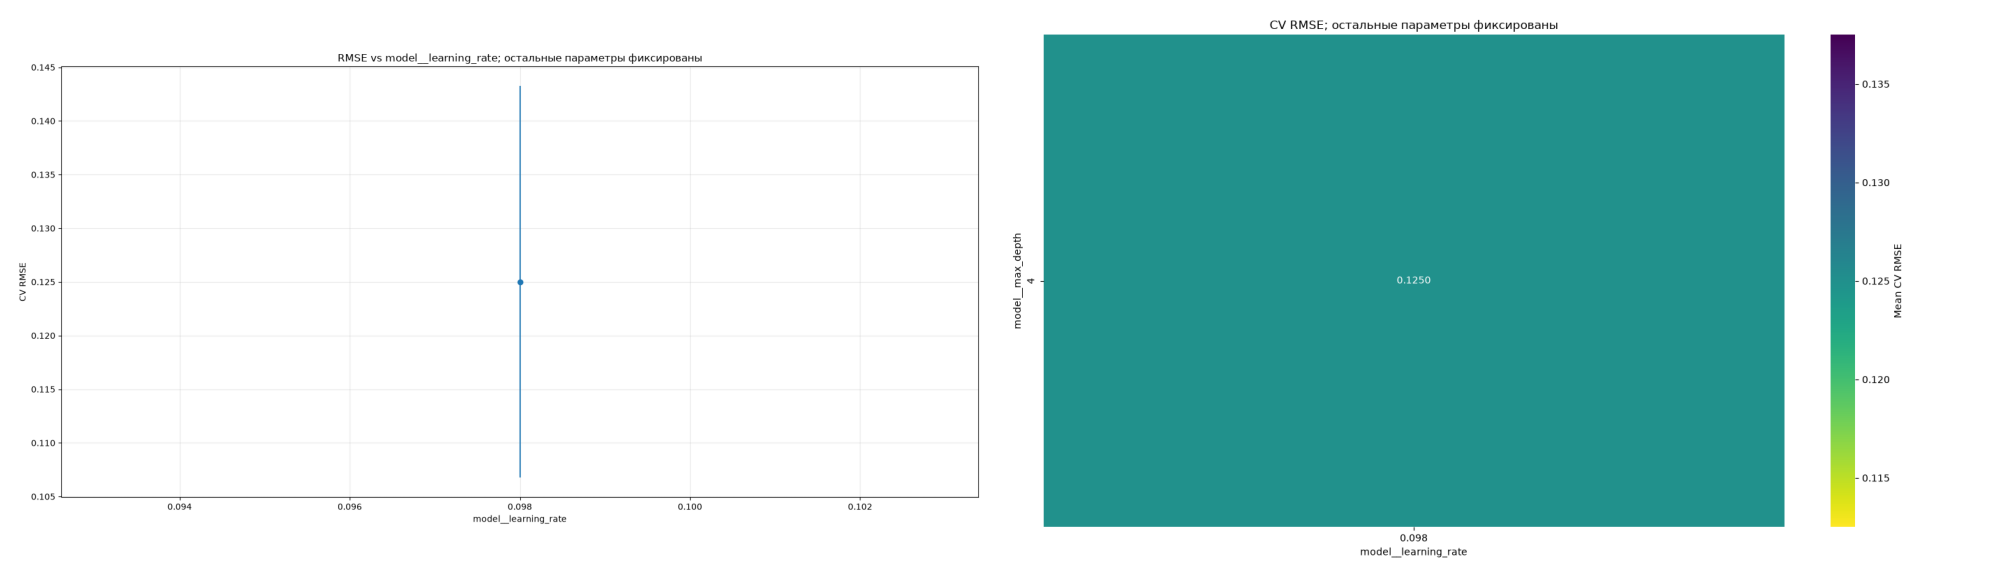

In [113]:
lightgbm_results = run_experiment(
    X_train, y_train,
    "lightgbm",
    lightgbm_pipeline,
    logger
)

### Optuna

In [ ]:
def suggest_lightgbm_params(trial):
    return {
        "model__boosting_type": trial.suggest_categorical(
            "model__boosting_type", ["gbdt",'dart']
        ),
        "model__n_estimators": trial.suggest_categorical(
            "model__n_estimators", [1000]
        ),
        "model__learning_rate": trial.suggest_float(
            "model__learning_rate",
            0.001,
            0.10,
            log=True,
        ),
        "model__max_depth": trial.suggest_categorical(
            "model__max_depth", [4,5,6,7,8]
        ),
        "model__subsample": trial.suggest_categorical(
            "model__subsample", [0.4,0.5,0.6,0.8,1]
        ),
        "model__colsample_bytree": trial.suggest_categorical(
            "model__colsample_bytree", [0.4,0.5,0.6,0.8,1]
        ),
        "model__reg_alpha": trial.suggest_float(
            "model__reg_alpha",
            0.001,
            0.10,
            log=True,
        ),
        "model__reg_alpha": trial.suggest_float(
            "model__reg_alpha",
            0.001,
            0.10,
            log=True,
        ),
        "model__min_child_samples": trial.suggest_categorical(
            "model__min_child_samples", [35,40,45,50,55]
        ),
        "model__min_child_weight": trial.suggest_float(
            "model__min_child_weight",
            0.01,
            1,
            log=True,
        ),
        "model__min_split_gain": trial.suggest_float(
            "model__min_split_gain",
            0.0001,
            0.01,
            log=True,
        ),
        "model__early_stopping_round":trial.suggest_categorical(
            "model__early_stopping_round", [25,30,35,40,45,50]
        )
    }

lightgbm_optuna_pipeline = {
    "lightgbm_optuna": {
        "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer(cat_boosting=True)),
            ("model", LGBMRegressor(allow_writing_files=False)),
        ]),
            "parameters_to_search": suggest_lightgbm_params,
            "search_type": "grid",
            "fit_param": {"model__random_seed": Config.seed,
                          "model__cat_features": FeatureTransformer.cat_cols,
                          "model__verbosity": -1,
                          "model__n_jobs" : -1,
                          'model__device' : 'gpu',
                          "model__objective": "regression",
                          "model__metric" : "rmse"
                          },
            "n_iter": 500, #для оптуны
            "plot_param": "model__learning_rate",
            "heatmap_params": ("model__learning_rate", "model__max_depth"),
            "shap_mode": "lightgbm",
            "cv": 5,
            "n_jobs": -1,
            }
        }

In [ ]:
lightgbm_optuna_results = run_optuna_experiment(
    X_train,
    y_train,
    "lightgbm_optuna",
    lightgbm_optuna_pipeline,
    logger
)

### SHAP и отбор признаков

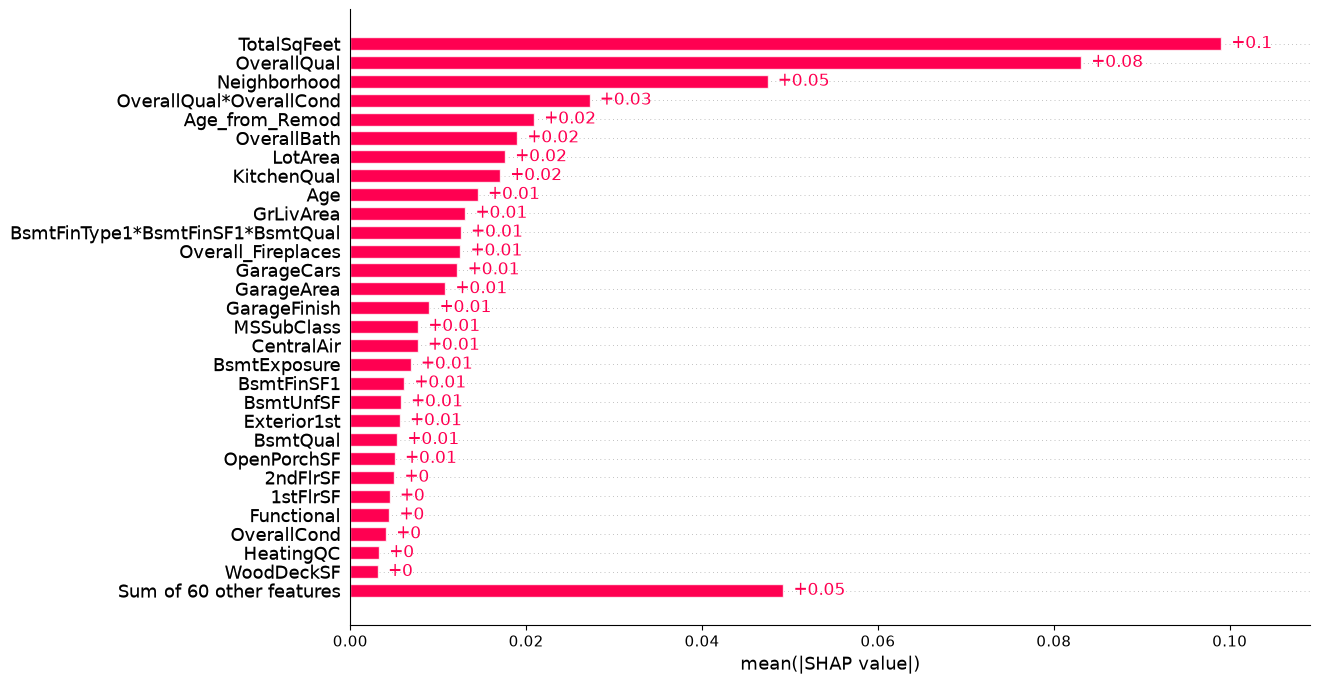

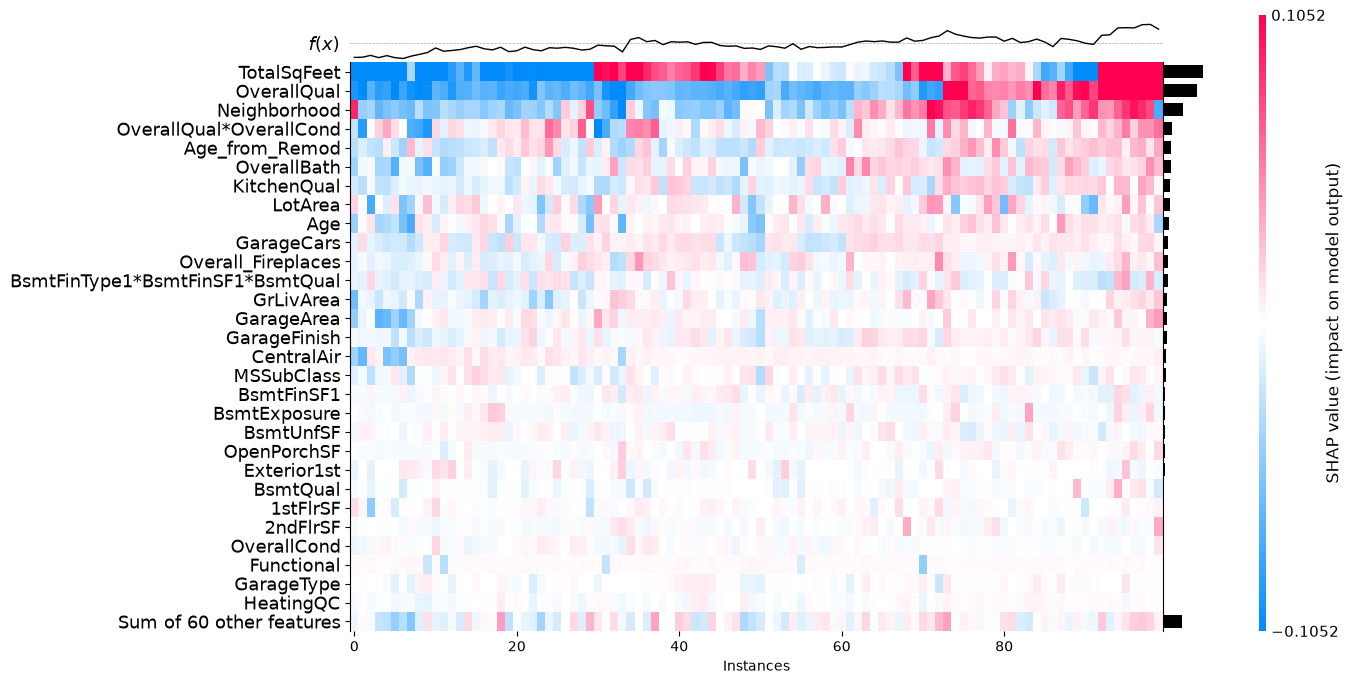

In [114]:
lightgbm_shap = run_shap(
    X_train,
    lightgbm_results,
    mode="lightgbm",
    logger = logger
)

Training:   0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mento

Training:   0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mento

Training:   0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mento

... (10 outputs left out)

Training:   0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mento

Best OOF: 0.12480425856041322, best mean val RMSE: 0.123316144363764, best val std: 0.018990680599274085, best feature amount: 81
-----Best searched params-----
model__boosting_type               gbdt
model__colsample_bytree             0.8
model__device                       cpu
model__early_stopping_round          30
model__learning_rate              0.098
model__max_depth                      4
model__metric                      rmse
model__min_child_samples             40
model__min_child_weight               1
model__min_split_gain            0.0005
model__n_estimators                2000
model__n_jobs                        -1
model__objective             regression
model__random_state                  42
model__reg_alpha                  0.008
model__reg_lambda                  0.04
model__subsample                    0.4
model__verbosity                     -1


,params,off_score,mean_val_score,std_val_score,feature_count,split0_val_score,split1_val_score,split2_val_score,split3_val_score,split4_val_score,...,param_model__min_split_gain,param_model__n_estimators,param_model__n_jobs,param_model__objective,param_model__random_state,param_model__reg_alpha,param_model__reg_lambda,param_model__subsample,param_model__verbosity,candidate_id
0,"{'model__boosting_type': 'gbdt', 'model__colsa...",0.124804,0.123316,0.018991,81,0.133124,0.125861,0.152209,0.105448,0.099939,...,0.0005,2000,-1,regression,42,0.008,0.04,0.4,-1,0
2,"{'model__boosting_type': 'gbdt', 'model__colsa...",0.125055,0.123779,0.017599,65,0.131018,0.125992,0.151690,0.107774,0.102422,...,0.0005,2000,-1,regression,42,0.008,0.04,0.4,-1,2
1,"{'model__boosting_type': 'gbdt', 'model__colsa...",0.125082,0.123729,0.018123,73,0.129940,0.127136,0.152604,0.107443,0.101524,...,0.0005,2000,-1,regression,42,0.008,0.04,0.4,-1,1
5,"{'model__boosting_type': 'gbdt', 'model__colsa...",0.125295,0.124008,0.017680,41,0.134359,0.127752,0.149194,0.108602,0.100133,...,0.0005,2000,-1,regression,42,0.008,0.04,0.4,-1,5
6,"{'model__boosting_type': 'gbdt', 'model__colsa...",0.125354,0.124198,0.016764,33,0.131449,0.126234,0.150684,0.108199,0.104424,...,0.0005,2000,-1,regression,42,0.008,0.04,0.4,-1,6
7,"{'model__boosting_type': 'gbdt', 'model__colsa...",0.126449,0.125187,0.017596,25,0.132989,0.127657,0.152675,0.108798,0.103813,...,0.0005,2000,-1,regression,42,0.008,0.04,0.4,-1,7
8,"{'model__boosting_type': 'gbdt', 'model__colsa...",0.126494,0.125234,0.017585,17,0.133394,0.126433,0.152980,0.109846,0.103518,...,0.0005,2000,-1,regression,42,0.008,0.04,0.4,-1,8
4,"{'model__boosting_type': 'gbdt', 'model__colsa...",0.126553,0.125227,0.018050,49,0.132095,0.125928,0.154950,0.107701,0.105460,...,0.0005,2000,-1,regression,42,0.008,0.04,0.4,-1,4
3,"{'model__boosting_type': 'gbdt', 'model__colsa...",0.126867,0.125673,0.017138,57,0.132595,0.127375,0.153209,0.109302,0.105885,...,0.0005,2000,-1,regression,42,0.008,0.04,0.4,-1,3


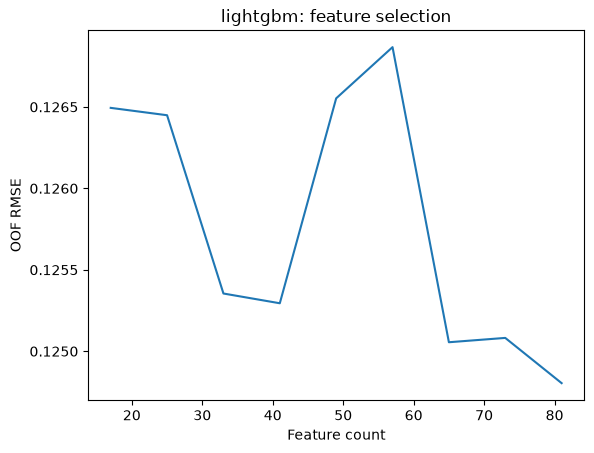

In [115]:
lightgbm_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=lightgbm_results['cv_folds'],
    importance=lightgbm_shap['importance'],
    search_results=lightgbm_results['best_results'],
    model_name="lightgbm",
    model_configs=lightgbm_pipeline,
    model_run_id=lightgbm_results['run_id'],
    logger=logger
)

if lightgbm_fs_results["best_oof_score"] < lightgbm_results['best_results']['best_oof_score']:
    ModelSaver.save_ensemble(lightgbm_fs_results['best_ensemble'],"lightgbm", save_fs=lightgbm_fs_results['best_results']['best_cols'])
else:
    ModelSaver.save_ensemble(lightgbm_results['best_ensemble'],"lightgbm")

## KNN

In [82]:
knn_pipeline = {"knn": {
    "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", KNeighborsRegressor()),
        ]),
    "parameters": {
            "model__n_neighbors": [8],
            "model__weights": ["distance"],
            "model__p": [1],
            "model__n_jobs": [-1],
        },
    "search_type": "grid",
    "fit_param": {},
    "n_iter": 250,
    "plot_param": "model__n_neighbors",
    "heatmap_params": ("model__n_neighbors", "model__p"),
    "shap_mode": "dnn",
    "cv": 5,
    "n_jobs": -1,
}}

Начинаем обучение 1 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF 0.17179213516397865, best mean val RMSE 0.17131553589880244, best_val_std 0.012514861099132867
Best searched params
model__n_jobs             -1
model__n_neighbors         8
model__p                   1
model__weights      distance


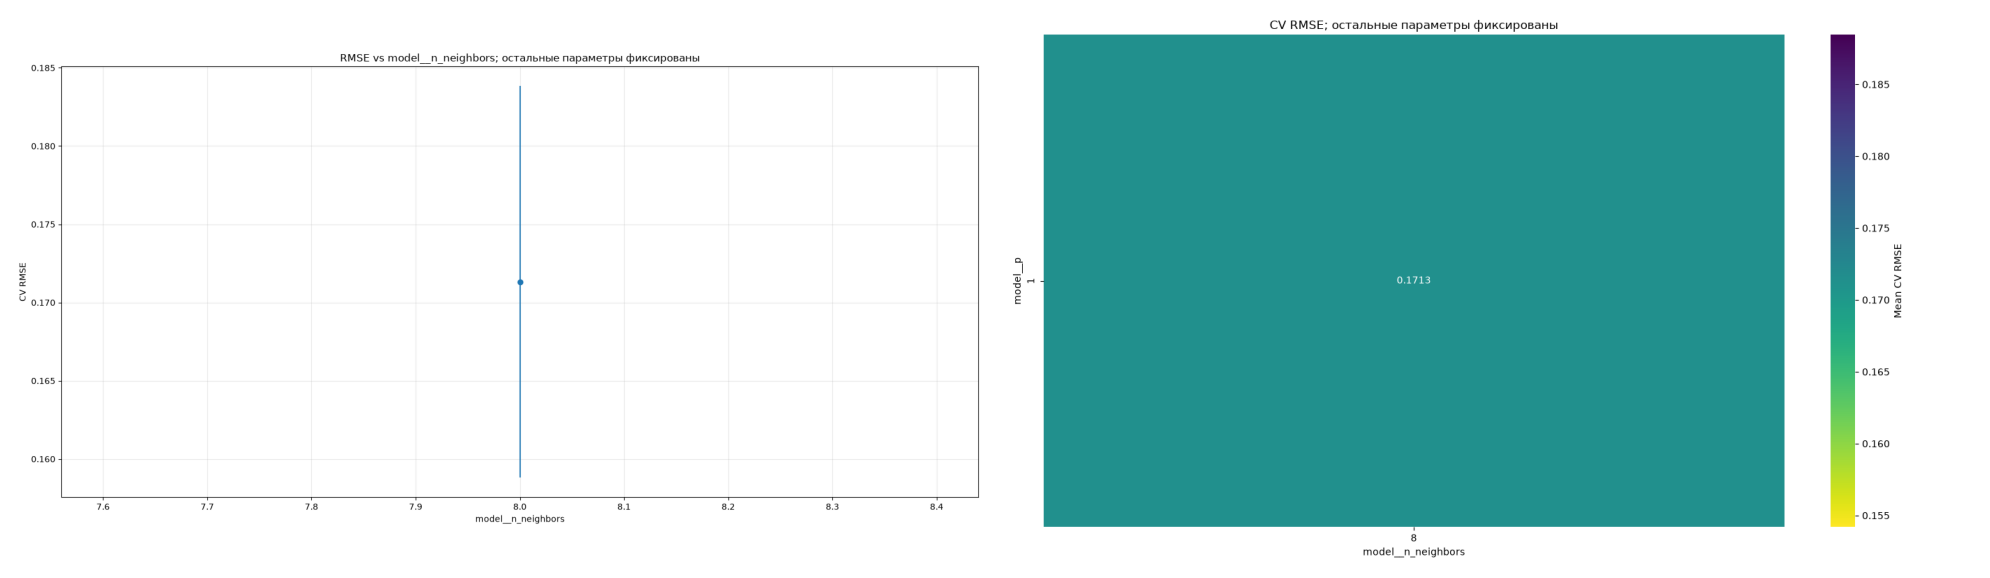

In [83]:
knn_results = run_experiment(
    X_train, y_train,
    "knn",
    knn_pipeline,
    logger
)

### Optuna

In [ ]:
def suggest_knn_params(trial):
    return {
        "model__n_neighbors": trial.suggest_categorical(
            "model__n_neighbors", list(map(int, np.linspace(4, 30, 15, dtype=int)))
        ),
        "model__weights": trial.suggest_categorical(
            "model__weights", ["uniform", "distance"]
        ),
        "model__p": trial.suggest_categorical(
            "model__p", [1, 2]
        ),
    }

knn_optuna_pipeline = {"knn_optuna": {
    "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", KNeighborsRegressor()),
        ]),
    "parameters_to_search": suggest_knn_params,
    "search_type": "grid",
    "fit_param": {"model__n_jobs": -1},
    "n_iter": 1,
    "plot_param": "model__n_neighbors",
    "heatmap_params": ("model__n_neighbors", "model__p"),
    "shap_mode": "knn",
    "cv": 5,
    "n_jobs": -1,
}}

In [ ]:
knn_optuna_results = run_optuna_experiment(
    X_train,
    y_train,
    "knn_optuna",
    knn_optuna_pipeline,
    logger
)

### SHAP и отбор признаков

In [ ]:
knn_optuna_shap = run_shap(
    X_train,
    knn_results,
    mode="dnn",
    logger=logger
)

In [ ]:
knn_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=knn_results['cv_folds'],
    importance=knn_optuna_shap['importance'],
    search_results=knn_results['best_results'],
    model_name="knn_optuna",
    model_configs=knn_pipeline,
    model_run_id=knn_results['run_id'],
    logger=logger
)
if knn_fs_results["best_oof_score"] < knn_results['best_results']['best_oof_score']:
    ModelSaver.save_ensemble(knn_fs_results['best_ensemble'],"knn", save_fs=knn_fs_results['best_results']['best_cols'])
else:
    ModelSaver.save_ensemble(knn_results['best_ensemble'],"knn")

## Decision Tree

In [85]:
decision_tree_pipeline = {"decision_tree": {
    "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", DecisionTreeRegressor()),
        ]),
    "parameters": {
            "model__max_depth": [6],
            "model__criterion": ["squared_error"],
            "model__splitter": ["best"],
            "model__min_samples_split": [36],
            "model__min_samples_leaf": [11],
            "model__max_leaf_nodes": [50],
            "model__min_impurity_decrease": [0],
            "model__random_state": [Config.seed],
        },
    "search_type": "grid",
    "fit_param": {},
    "n_iter": 250,
    "plot_param": "model__max_depth",
    "heatmap_params": ("model__max_depth", "model__min_samples_leaf"),
    "shap_mode": "tree",
    "cv": 5,
    "n_jobs": -1,
}}

Начинаем обучение 1 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF 0.1880423933179351, best mean val RMSE 0.1875070880962946, best_val_std 0.01384111031316374
Best searched params
model__criterion              squared_error
model__max_depth                          6
model__max_leaf_nodes                    50
model__min_impurity_decrease              0
model__min_samples_leaf                  11
model__min_samples_split                 36
model__random_state                      42
model__splitter                        best


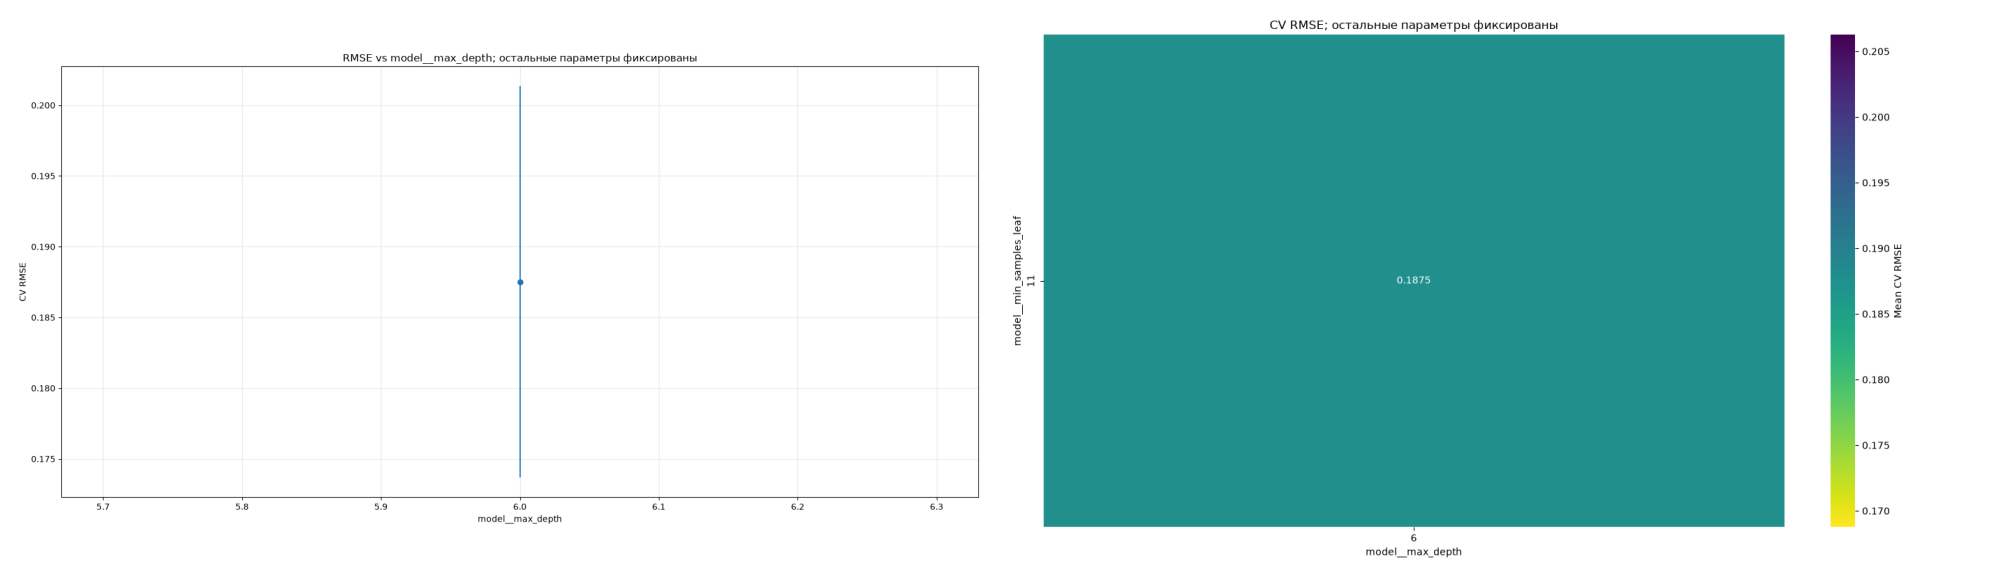

In [86]:
decision_tree_results = run_experiment(
    X_train, y_train,
    "decision_tree",
    decision_tree_pipeline,
    logger
)

### Optuna

In [ ]:
def suggest_decision_tree_params(trial):
    return {
        "model__max_depth": trial.suggest_categorical(
            "model__max_depth", [6]
        ),
        "model__criterion": trial.suggest_categorical(
            "model__criterion", ["squared_error"]
        ),
        "model__splitter": trial.suggest_categorical(
            "model__splitter", ["best"]
        ),
        "model__min_samples_split": trial.suggest_categorical(
            "model__min_samples_split", [36]
        ),
        "model__min_samples_leaf": trial.suggest_categorical(
            "model__min_samples_leaf", [11]
        ),
        "model__max_leaf_nodes": trial.suggest_categorical(
            "model__max_leaf_nodes", [50]
        ),
        "model__min_impurity_decrease": trial.suggest_categorical(
            "model__min_impurity_decrease", [0]
        ),
    }

decision_tree_optuna_pipeline = {"decision_tree_optuna": {
    "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", DecisionTreeRegressor()),
        ]),
    "parameters_to_search": suggest_decision_tree_params,
    "search_type": "grid",
    "fit_param": {"model__random_state": Config.seed},
    "n_iter": 1,
    "plot_param": "model__max_depth",
    "heatmap_params": ("model__max_depth", "model__min_samples_leaf"),
    "shap_mode": "tree",
    "cv": 5,
    "n_jobs": -1,
}}

In [ ]:
decision_tree_optuna_results = run_optuna_experiment(
    X_train,
    y_train,
    "decision_tree_optuna",
    decision_tree_optuna_pipeline,
    logger
)

### SHAP и отбор признаков

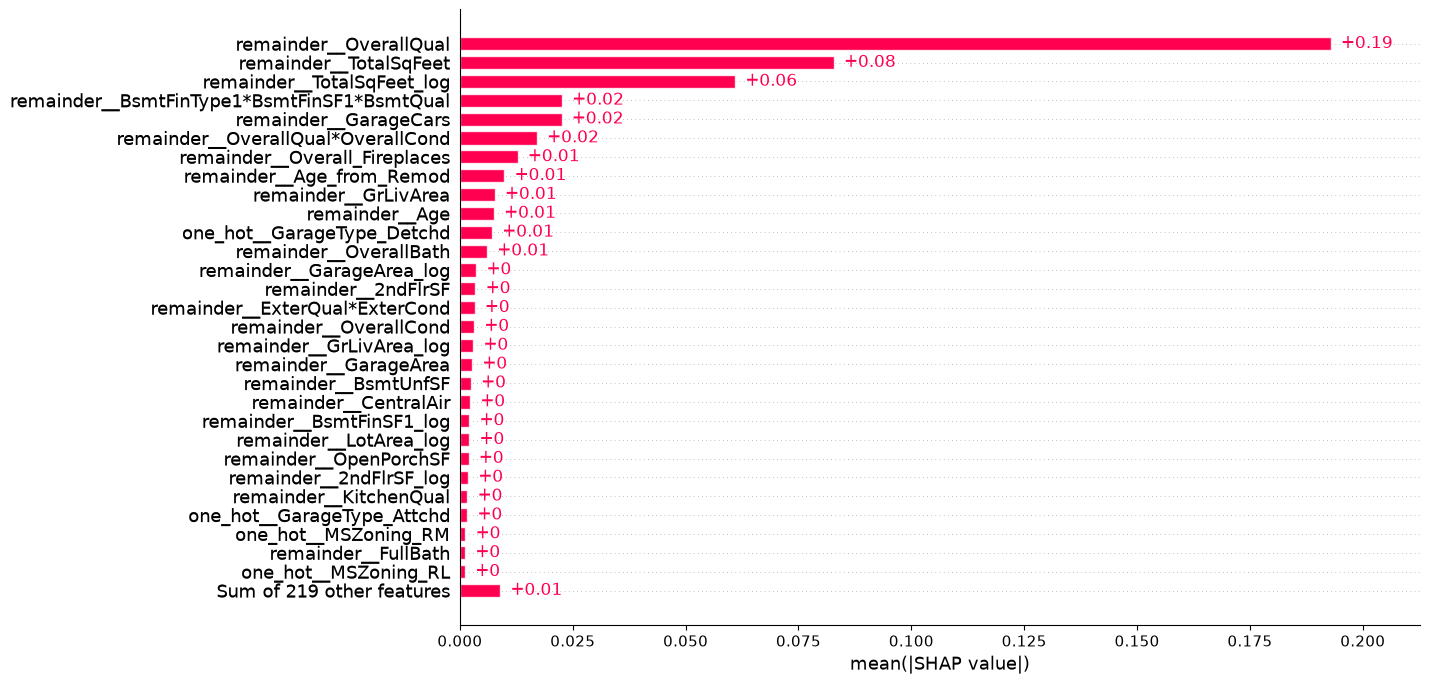

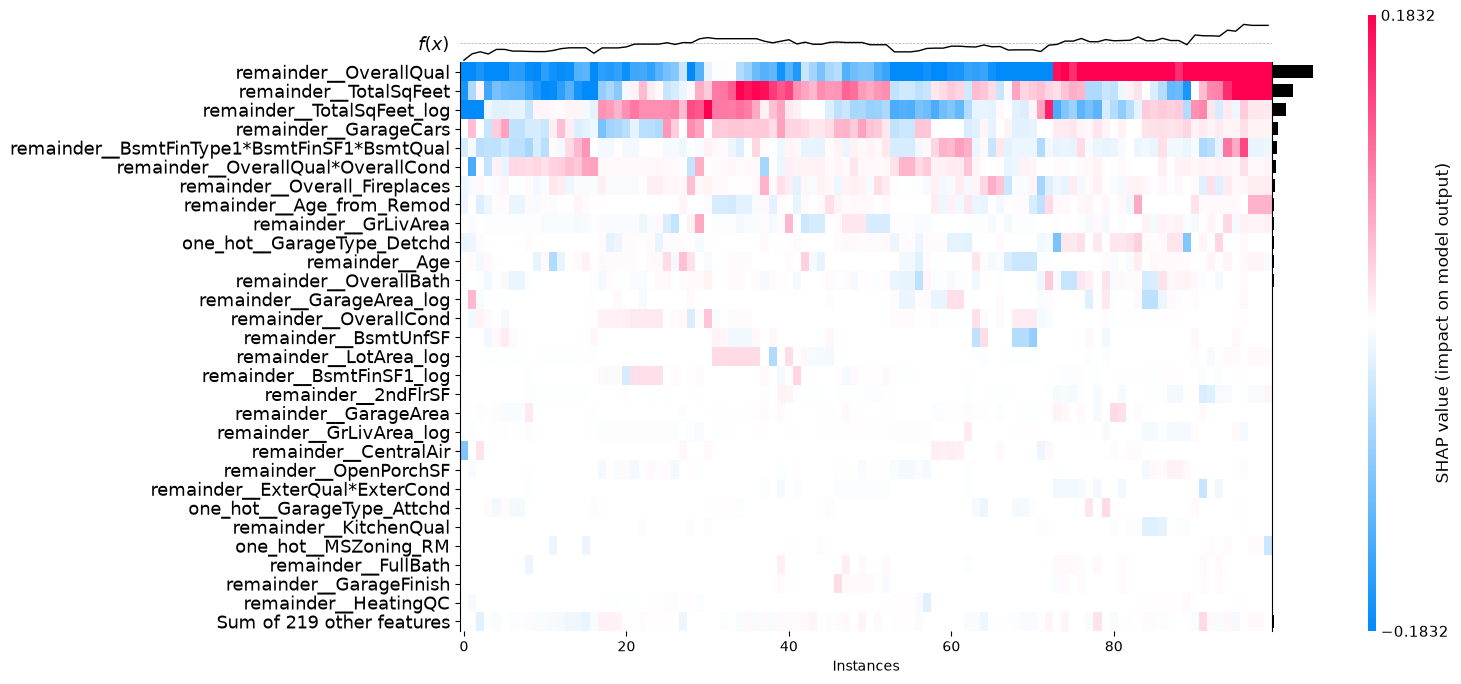

In [87]:
decision_tree_optuna_shap = run_shap(
    X_train,
    decision_tree_results,
    mode="tree",
    logger=logger
)

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

... (2 outputs left out)

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF: 0.18418160007134562, best mean val RMSE: 0.18354110732146553, best val std: 0.015005651007346875, best feature amount: 17
-----Best searched params-----
model__criterion              squared_error
model__max_depth                          6
model__max_leaf_nodes                    50
model__min_impurity_decrease              0
model__min_samples_leaf                  11
model__min_samples_split                 36
model__random_state                      42
model__splitter                        best


,params,off_score,mean_val_score,std_val_score,feature_count,split0_val_score,split1_val_score,split2_val_score,split3_val_score,split4_val_score,param_model__criterion,param_model__max_depth,param_model__max_leaf_nodes,param_model__min_impurity_decrease,param_model__min_samples_leaf,param_model__min_samples_split,param_model__random_state,param_model__splitter,candidate_id
8,"{'model__criterion': 'squared_error', 'model__...",0.184182,0.183541,0.015006,23,0.191222,0.188417,0.204364,0.171971,0.161732,squared_error,6,50,0,11,36,42,best,8
7,"{'model__criterion': 'squared_error', 'model__...",0.187297,0.186886,0.012038,35,0.192859,0.191033,0.204129,0.173299,0.173111,squared_error,6,50,0,11,36,42,best,7
2,"{'model__criterion': 'squared_error', 'model__...",0.188024,0.187489,0.013838,196,0.192334,0.190092,0.209610,0.173305,0.172105,squared_error,6,50,0,11,36,42,best,2
1,"{'model__criterion': 'squared_error', 'model__...",0.188024,0.187489,0.013838,208,0.192334,0.190092,0.209610,0.173305,0.172105,squared_error,6,50,0,11,36,42,best,1
0,"{'model__criterion': 'squared_error', 'model__...",0.188042,0.187507,0.013841,240,0.192334,0.190182,0.209610,0.173305,0.172105,squared_error,6,50,0,11,36,42,best,0
4,"{'model__criterion': 'squared_error', 'model__...",0.188042,0.187507,0.013841,148,0.192334,0.190182,0.209610,0.173305,0.172105,squared_error,6,50,0,11,36,42,best,4
3,"{'model__criterion': 'squared_error', 'model__...",0.188235,0.187677,0.014140,176,0.192334,0.190092,0.210551,0.173305,0.172105,squared_error,6,50,0,11,36,42,best,3
5,"{'model__criterion': 'squared_error', 'model__...",0.188235,0.187677,0.014140,124,0.192334,0.190092,0.210551,0.173305,0.172105,squared_error,6,50,0,11,36,42,best,5
6,"{'model__criterion': 'squared_error', 'model__...",0.188435,0.187886,0.014037,65,0.192914,0.190749,0.210154,0.173508,0.172105,squared_error,6,50,0,11,36,42,best,6


PicklingError: Can't pickle <class 'src.feature.features.FeatureTransformer'>: it's not the same object as src.feature.features.FeatureTransformer

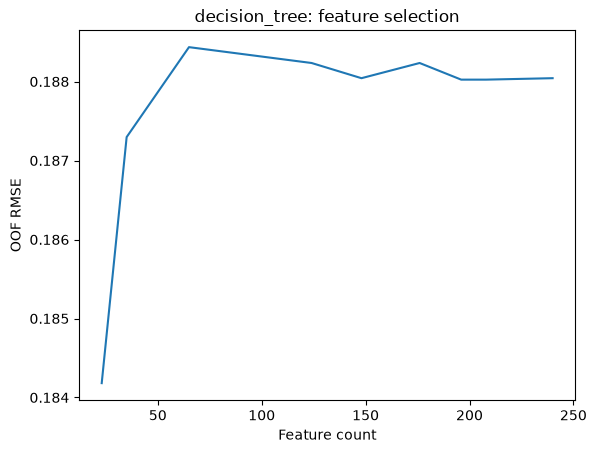

In [116]:
decision_tree_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=decision_tree_results['cv_folds'],
    importance=decision_tree_optuna_shap['importance'],
    search_results=decision_tree_results['best_results'],
    model_name="decision_tree",
    model_configs=decision_tree_pipeline,
    model_run_id=decision_tree_results['run_id'],
    logger=logger
)
if decision_tree_fs_results["best_oof_score"] < decision_tree_results['best_results']['best_oof_score']:
    ModelSaver.save_ensemble(decision_tree_fs_results['best_ensemble'],"decision_tree", save_fs=decision_tree_fs_results['best_results']['best_cols'])
else:
    ModelSaver.save_ensemble(decision_tree_results['best_ensemble'],"decision_tree")

## Random Forest

In [117]:
random_forest_pipeline = {"random_forest": {
    "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", RandomForestRegressor()),
        ]),
    "parameters": {
            # bootstrap=True
            "model__n_estimators": [1000],  # np.linspace(1, 100, 5, dtype=int)
            "model__max_depth": [14],  # 13
            "model__criterion": ["squared_error"],
            "model__n_jobs": [-1],
            "model__min_samples_split": [10],  # np.linspace(10, 100, 5, dtype=int)
            "model__min_samples_leaf": [5],  # np.linspace(5, 15, 5, dtype=int); min_samples_leaf: np.int64(6)
            "model__max_leaf_nodes": [100],  # 75
            "model__min_impurity_decrease": [0],
            "model__max_features": [None],  # "sqrt", "log2"
            "model__bootstrap": [True],
            "model__max_samples": [0.8],
            "model__oob_score": [True],
            "model__random_state": [Config.seed],
        },
    "search_type": "grid",
    "fit_param": {},
    "n_iter": 250,
    "plot_param": "model__max_leaf_nodes",
    "heatmap_params": ("model__max_leaf_nodes", "model__max_depth"),
    "shap_mode": "tree",
    "cv": 5,
    "n_jobs": -1,
}}

Начинаем обучение 1 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF 0.14411948370307778, best mean val RMSE 0.14313990819970115, best_val_std 0.016523360875414048
Best searched params
model__bootstrap                       True
model__criterion              squared_error
model__max_depth                         14
model__max_features                    None
model__max_leaf_nodes                   100
model__max_samples                      0.8
model__min_impurity_decrease              0
model__min_samples_leaf                   5
model__min_samples_split                 10
model__n_estimators                    1000
model__n_jobs                            -1
model__oob_score                       True
model__random_state                      42


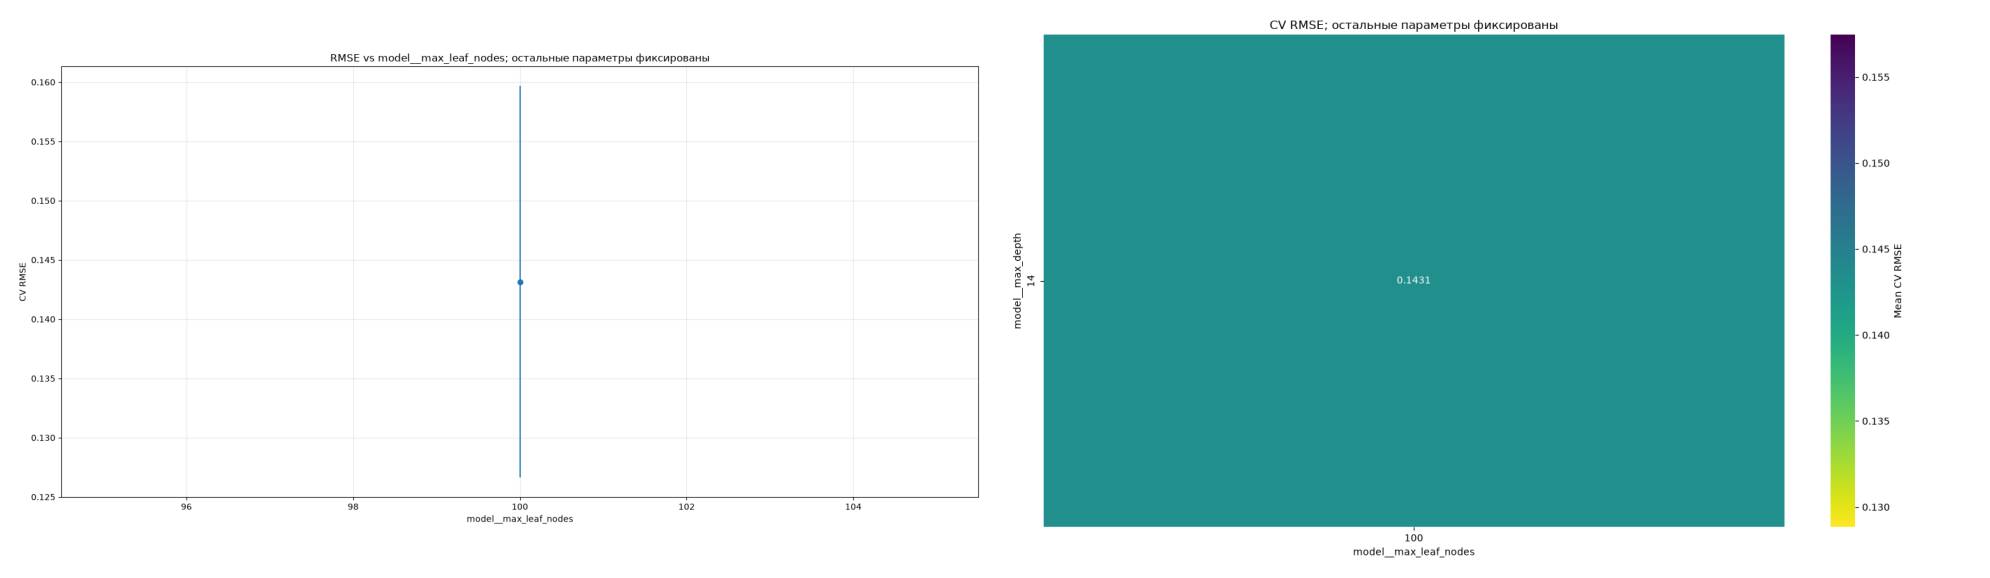

In [118]:
random_forest_results = run_experiment(
    X_train, y_train,
    "random_forest",
    random_forest_pipeline,
    logger
)

### Optuna

In [ ]:
def suggest_random_forest_params(trial):
    return {
        "model__n_estimators": trial.suggest_int(
            "model__n_estimators", 100,2000, step=100
        ),
        "model__max_depth": trial.suggest_int(
            "model__max_depth", 10,20, step=1
        ),
        "model__min_samples_split": trial.suggest_int(
            "model__min_samples_split", 5,50, step=5
        ),
        "model__min_samples_leaf": trial.suggest_int(
            "model__min_samples_leaf", 5,50, step=5
        ),
        "model__max_leaf_nodes": trial.suggest_int(
            "model__max_leaf_nodes", 50,100, step=5
        ),
        "model__min_impurity_decrease": trial.suggest_float(
            "model__min_impurity_decrease",
            0.01,
            20,
            log=True,
        ),
        "model__max_features": trial.suggest_categorical(
            "model__max_features", [0.4,0.6,0.8,1.0]
        ),
        "model__max_samples": trial.suggest_categorical(
            "model__max_samples", [0.4,0.6,0.8,1.0]
        ),
        "model__oob_score": trial.suggest_categorical(
            "model__oob_score", [True, False]
        ),
    }

random_forest_optuna_pipeline = {"random_forest_optuna": {
    "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", RandomForestRegressor()),
        ]),
    "parameters_to_search": suggest_random_forest_params,
    "search_type": "grid",
    "fit_param": {"model__n_jobs": -1,
                "model__random_state": Config.seed,
                'model__bootstrap':True,
                "model__criterion":"squared_error"},
    "n_iter": 300,
    "plot_param": "model__n_estimators",
    "heatmap_params": ("model__n_estimators", "model__max_depth"),
    "shap_mode": "tree",
    "cv": 5,
    "n_jobs": -1,
}}

In [ ]:
random_forest_optuna_results = run_optuna_experiment(
    X_train,
    y_train,
    "random_forest_optuna",
    random_forest_optuna_pipeline,
    logger
)

### SHAP и отбор признаков

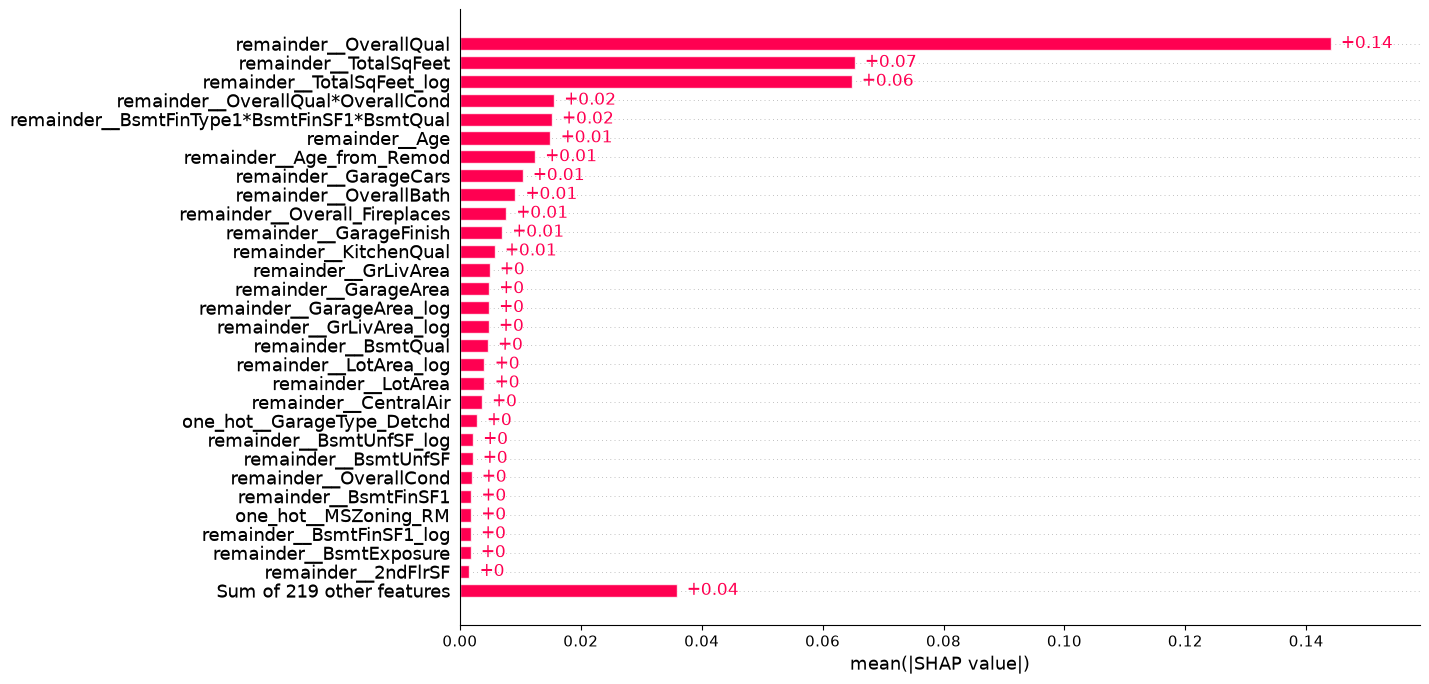

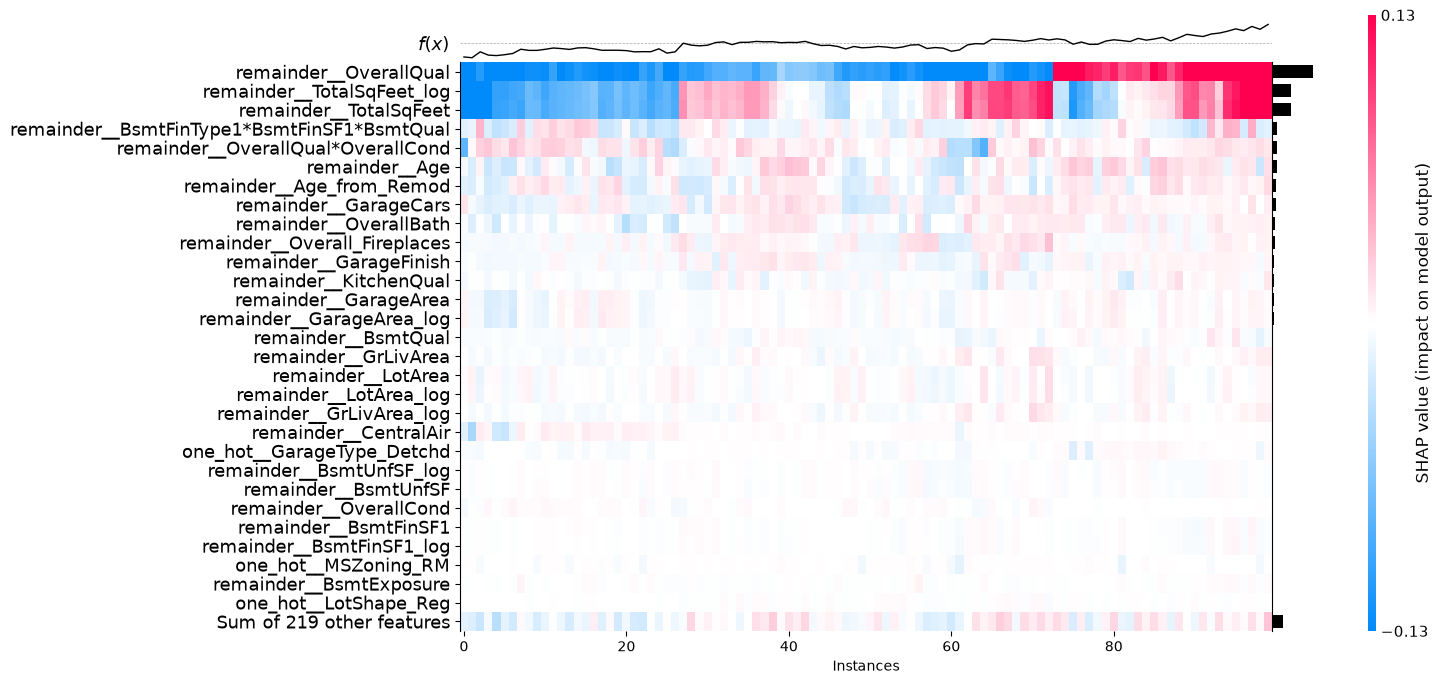

In [119]:
random_forest_shap = run_shap(
    X_train,
    random_forest_results,
    mode="tree",
    logger=logger
)

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF: 0.14229028147157963, best mean val RMSE: 0.1412784115993505, best val std: 0.016690951404614834, best feature amount: 33
-----Best searched params-----
model__bootstrap                       True
model__criterion              squared_error
model__max_depth                         14
model__max_features                    None
model__max_leaf_nodes                   100
model__max_samples                      0.8
model__min_impurity_decrease              0
model__min_samples_leaf                   5
model__min_samples_split                 10
model__n_estimators                    1000
model__n_jobs                            -1
model__oob_score                       True
model__random_state                      42


,params,off_score,mean_val_score,std_val_score,feature_count,split0_val_score,split1_val_score,split2_val_score,split3_val_score,split4_val_score,...,param_model__max_leaf_nodes,param_model__max_samples,param_model__min_impurity_decrease,param_model__min_samples_leaf,param_model__min_samples_split,param_model__n_estimators,param_model__n_jobs,param_model__oob_score,param_model__random_state,candidate_id
6,"{'model__bootstrap': True, 'model__criterion':...",0.142290,0.141278,0.016691,84,0.145458,0.144177,0.168874,0.125423,0.122460,...,100,0.8,0,5,10,1000,-1,True,42,6
7,"{'model__bootstrap': True, 'model__criterion':...",0.142605,0.141604,0.016615,49,0.145564,0.144562,0.169131,0.125953,0.122810,...,100,0.8,0,5,10,1000,-1,True,42,7
5,"{'model__bootstrap': True, 'model__criterion':...",0.143146,0.142139,0.016698,92,0.145744,0.145729,0.169727,0.125790,0.123703,...,100,0.8,0,5,10,1000,-1,True,42,5
4,"{'model__bootstrap': True, 'model__criterion':...",0.143839,0.142825,0.016800,105,0.146763,0.145846,0.170677,0.126967,0.123870,...,100,0.8,0,5,10,1000,-1,True,42,4
3,"{'model__bootstrap': True, 'model__criterion':...",0.143855,0.142872,0.016531,127,0.147204,0.145356,0.170273,0.127381,0.124148,...,100,0.8,0,5,10,1000,-1,True,42,3
2,"{'model__bootstrap': True, 'model__criterion':...",0.143946,0.142968,0.016497,180,0.147527,0.145514,0.170173,0.127363,0.124263,...,100,0.8,0,5,10,1000,-1,True,42,2
1,"{'model__bootstrap': True, 'model__criterion':...",0.144059,0.143077,0.016543,209,0.147637,0.145630,0.170366,0.127389,0.124362,...,100,0.8,0,5,10,1000,-1,True,42,1
0,"{'model__bootstrap': True, 'model__criterion':...",0.144075,0.143096,0.016516,224,0.147634,0.145612,0.170362,0.127447,0.124425,...,100,0.8,0,5,10,1000,-1,True,42,0
8,"{'model__bootstrap': True, 'model__criterion':...",0.144960,0.144003,0.016368,17,0.148833,0.148114,0.170041,0.128703,0.124323,...,100,0.8,0,5,10,1000,-1,True,42,8


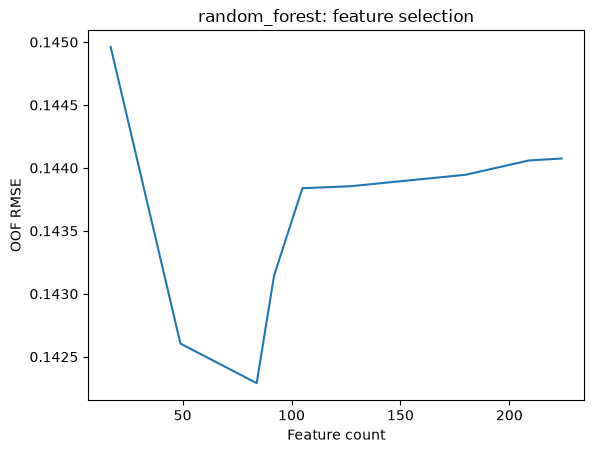

In [120]:
random_forest_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=random_forest_results['cv_folds'],
    importance=random_forest_shap['importance'],
    search_results=random_forest_results['best_results'],
    model_name="random_forest",
    model_configs=random_forest_pipeline,
    model_run_id=random_forest_results['run_id'],
    logger=logger
)
if random_forest_fs_results["best_oof_score"] < random_forest_results['best_results']['best_oof_score']:
    ModelSaver.save_ensemble(random_forest_fs_results['best_ensemble'],"random_forest", save_fs=random_forest_fs_results['best_results']['best_cols'])
else:
    ModelSaver.save_ensemble(random_forest_results['best_ensemble'],"random_forest")

## XGBoost

In [121]:
xgboost_pipeline = {"xgboost": {
    "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", XGBRegressor()),
        ]),
    "parameters": {
            "model__device": ["cuda"],
            "model__booster": ["gbtree"],
            "model__tree_method": ["hist"],
            "model__n_estimators": [1000],  # np.linspace(1, 100, 5, dtype=int); лучшее 12
            "model__learning_rate": [np.float64(0.013190161120540767)],  # [np.float64(0.0775)]
            "model__max_depth": [6],  # [6, 8, 10, 12, 14]; лучшее 10 для случайного леса
            "model__min_child_weight": [0.03794613934217169],  # np.linspace(1, 10, 5, dtype=int)
            "model__n_jobs": [1],
            "model__subsample": [0.4],  # [0.6, 0.8, 1.0]
            "model__colsample_bytree": [0.75],  # [0.65, 0.7, 0.75]
            "model__reg_alpha": [0.0193336968922133],  # [0, 0.01, 0.1, 1]
            "model__reg_lambda": [0.032333649917330995],  # [0.01, 0.1, 0.5, 5, 10]
            "model__gamma": [0.017362357647552687],  # np.linspace(0.01, 0.1, 10)
            "model__objective": ["reg:squarederror"],
            "model__eval_metric": ["rmse"],  # RMSE для регрессии
            "model__random_state": [Config.seed],
        },
    "search_type": "grid",
    "fit_param": {},
    "n_iter": 1,
    "plot_param": "model__learning_rate",
    "heatmap_params": ("model__learning_rate", "model__n_estimators"),
    "shap_mode": "tree",
    "cv": 5,
    "n_jobs": 1,
}}

Начинаем обучение 1 комбинаций


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF 0.12713958305423081, best mean val RMSE 0.12529598258436386, best_val_std 0.02134537417413177
Best searched params
model__booster                     gbtree
model__colsample_bytree              0.75
model__device                        cuda
model__eval_metric                   rmse
model__gamma                     0.017362
model__learning_rate              0.01319
model__max_depth                        6
model__min_child_weight          0.037946
model__n_estimators                  1000
model__n_jobs                           1
model__objective         reg:squarederror
model__random_state                    42
model__reg_alpha                 0.019334
model__reg_lambda                0.032334
model__subsample                      0.4
model__tree_method                   hist


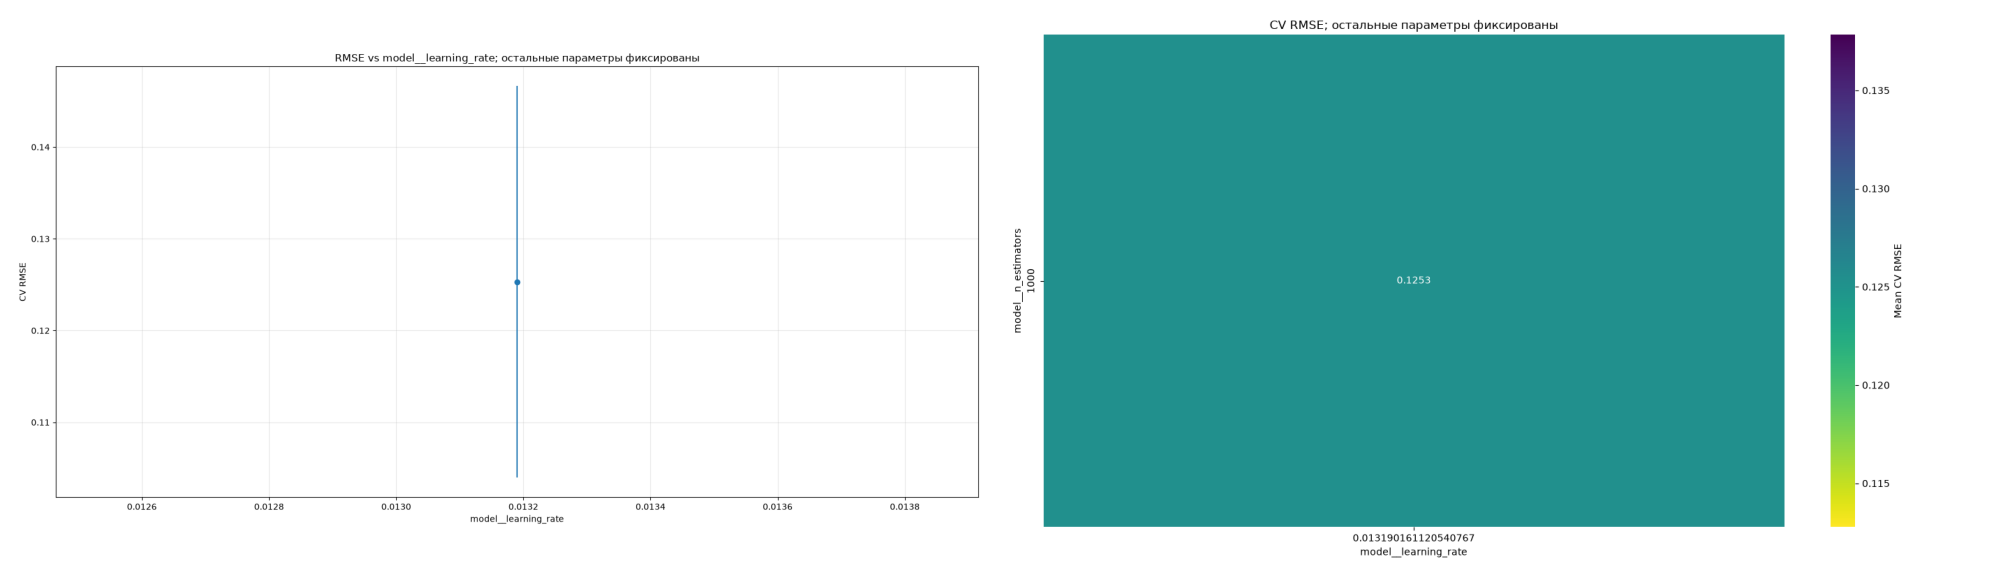

In [122]:
xgboost_results = run_experiment(
    X_train, y_train,
    "xgboost",
    xgboost_pipeline,
    logger
)

### Optuna

In [ ]:
def suggest_xgboost_params(trial):
    return {
        "model__booster": trial.suggest_categorical(
            "model__booster", ["gbtree"]
        ),
        "model__tree_method": trial.suggest_categorical(
            "model__tree_method", ["hist"]
        ),
        "model__n_estimators": trial.suggest_categorical(
            "model__n_estimators", [1000]
        ),
        "model__learning_rate": trial.suggest_float(
            "model__learning_rate",
            0.001,
            0.10,
            log=True,
        ),
        "model__max_depth": trial.suggest_categorical(
            "model__max_depth", [4,5,6,7,8]
        ),
        "model__min_child_weight": trial.suggest_float(
            "model__min_child_weight",
            0.01,
            20,
            log=True,
        ),
        "model__subsample": trial.suggest_categorical(
            "model__subsample", [0.4,0.5,0.6,0.8,1]
        ),
        "model__reg_alpha": trial.suggest_float(
            "model__reg_alpha",
            0.001,
            0.10,
            log=True,
        ),
        "model__reg_lambda": trial.suggest_float(
            "model__reg_lambda",
            0.001,
            0.10,
            log=True,
        ),
        "model__gamma": trial.suggest_float(
            "model__gamma",
            0.01,
            0.1,
            log=True,
        ),
        'model__colsample_bytree': trial.suggest_categorical(
            "model__colsample_bytree", [0.5, 0.65, 0.7, 0.75, 0.8,1]
        ),
    }

xgboost_optuna_pipeline = {"xgboost_optuna": {
    "pipeline": Pipeline([
            ("feature_transform", FeatureTransformer()),
            ("encoder", clone(encoder_transformer)),
            ("scaler", StandardScaler()),
            ("model", XGBRegressor()),
        ]),
    "parameters_to_search": suggest_xgboost_params,
    "search_type": "grid",
    "fit_param": {"model__device": "cuda",
                  "model__n_jobs": -1,
                  "model__random_state": Config.seed,
                  "model__objective": "reg:squarederror",
                  "model__eval_metric": "rmse"},
    "n_iter": 500,
    "plot_param": "model__learning_rate",
    "heatmap_params": ("model__learning_rate", "model__n_estimators"),
    "shap_mode": "tree",
    "cv": 5,
    "n_jobs": -1,
}}

In [ ]:
xgboost_optuna_results = run_optuna_experiment(
    X_train,
    y_train,
    "xgboost_optuna",
    xgboost_optuna_pipeline,
    logger
)

### SHAP и отбор признаков

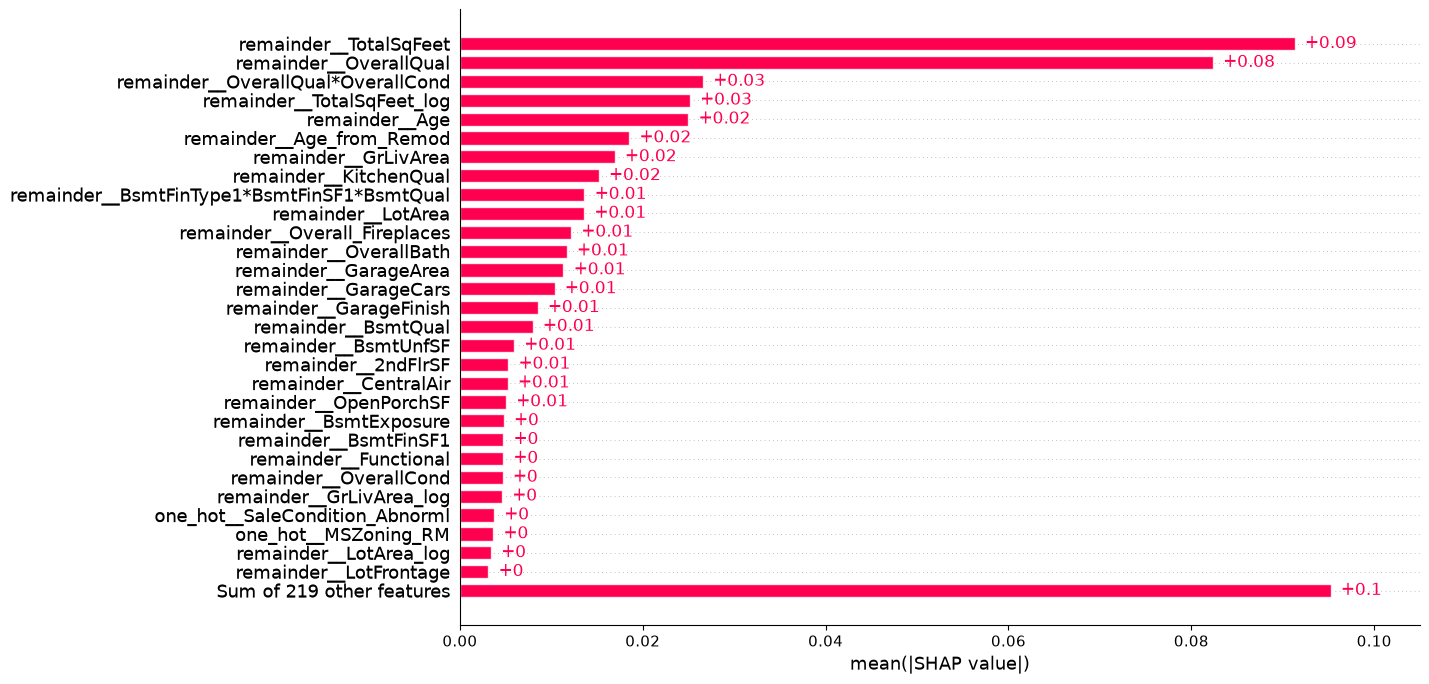

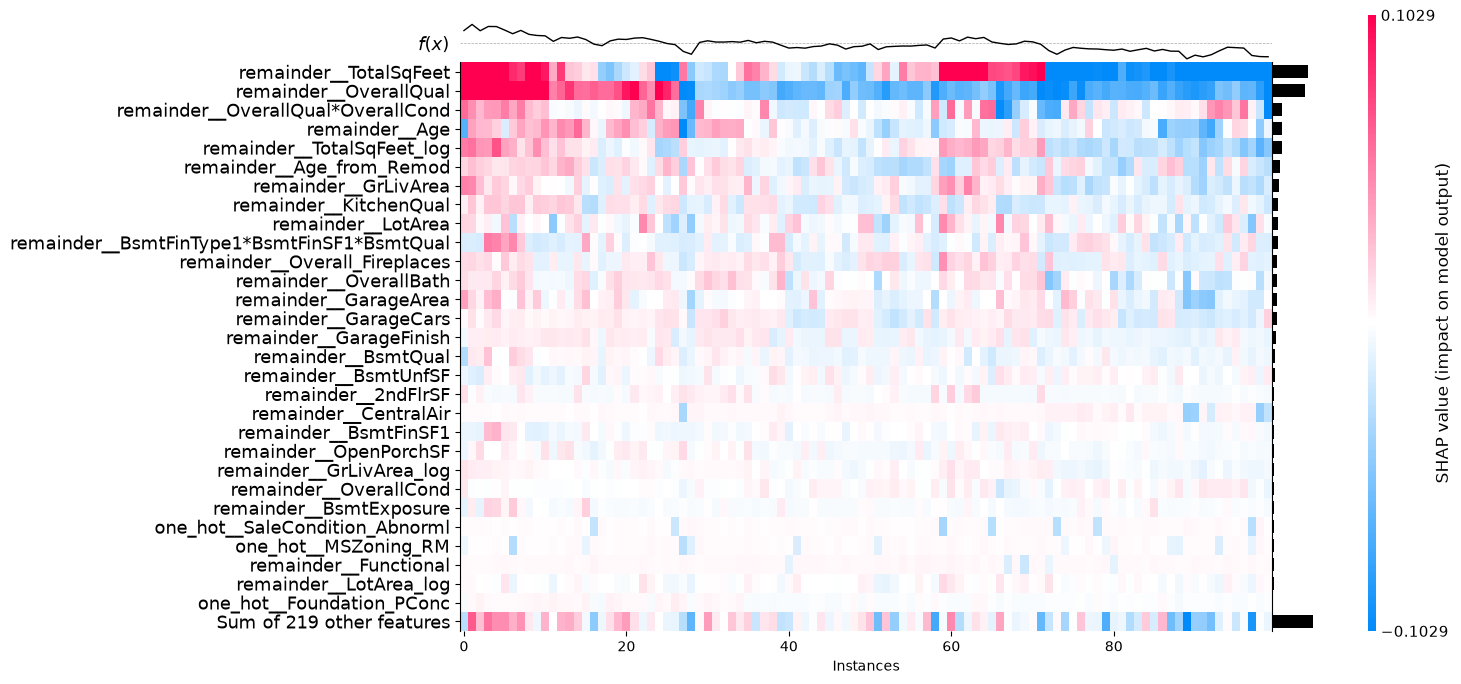

In [123]:
xgboost_shap = run_shap(
    X_train,
    xgboost_results,
    mode="tree",
    logger=logger
)

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Best OOF: 0.1254597551093981, best mean val RMSE: 0.1233197247292304, best val std: 0.0228473012320703, best feature amount: 33
-----Best searched params-----
model__booster                     gbtree
model__colsample_bytree              0.75
model__device                        cuda
model__eval_metric                   rmse
model__gamma                     0.017362
model__learning_rate              0.01319
model__max_depth                        6
model__min_child_weight          0.037946
model__n_estimators                  1000
model__n_jobs                           1
model__objective         reg:squarederror
model__random_state                    42
model__reg_alpha                 0.019334
model__reg_lambda                0.032334
model__subsample                      0.4
model__tree_method                   hist


,params,off_score,mean_val_score,std_val_score,feature_count,split0_val_score,split1_val_score,split2_val_score,split3_val_score,split4_val_score,...,param_model__min_child_weight,param_model__n_estimators,param_model__n_jobs,param_model__objective,param_model__random_state,param_model__reg_alpha,param_model__reg_lambda,param_model__subsample,param_model__tree_method,candidate_id
6,"{'model__booster': 'gbtree', 'model__colsample...",0.125460,0.123320,0.022847,113,0.125060,0.139149,0.155981,0.101956,0.094454,...,0.037946,1000,1,reg:squarederror,42,0.019334,0.032334,0.4,hist,6
0,"{'model__booster': 'gbtree', 'model__colsample...",0.125903,0.124175,0.020568,224,0.124434,0.136715,0.155308,0.105639,0.098778,...,0.037946,1000,1,reg:squarederror,42,0.019334,0.032334,0.4,hist,0
3,"{'model__booster': 'gbtree', 'model__colsample...",0.126196,0.124299,0.021569,180,0.126663,0.137569,0.155971,0.103989,0.097303,...,0.037946,1000,1,reg:squarederror,42,0.019334,0.032334,0.4,hist,3
2,"{'model__booster': 'gbtree', 'model__colsample...",0.126289,0.124468,0.021139,200,0.125574,0.138974,0.155154,0.103482,0.099158,...,0.037946,1000,1,reg:squarederror,42,0.019334,0.032334,0.4,hist,2
5,"{'model__booster': 'gbtree', 'model__colsample...",0.126699,0.124764,0.021835,129,0.124899,0.139732,0.156808,0.104478,0.097903,...,0.037946,1000,1,reg:squarederror,42,0.019334,0.032334,0.4,hist,5
1,"{'model__booster': 'gbtree', 'model__colsample...",0.126910,0.125118,0.021025,215,0.126342,0.137245,0.157110,0.104701,0.100193,...,0.037946,1000,1,reg:squarederror,42,0.019334,0.032334,0.4,hist,1
4,"{'model__booster': 'gbtree', 'model__colsample...",0.127185,0.125290,0.021642,166,0.128162,0.138931,0.156615,0.104687,0.098054,...,0.037946,1000,1,reg:squarederror,42,0.019334,0.032334,0.4,hist,4
7,"{'model__booster': 'gbtree', 'model__colsample...",0.127958,0.126026,0.021920,86,0.127029,0.142028,0.157189,0.104603,0.099282,...,0.037946,1000,1,reg:squarederror,42,0.019334,0.032334,0.4,hist,7
8,"{'model__booster': 'gbtree', 'model__colsample...",0.128733,0.126768,0.022173,41,0.128235,0.146528,0.155398,0.103020,0.100657,...,0.037946,1000,1,reg:squarederror,42,0.019334,0.032334,0.4,hist,8


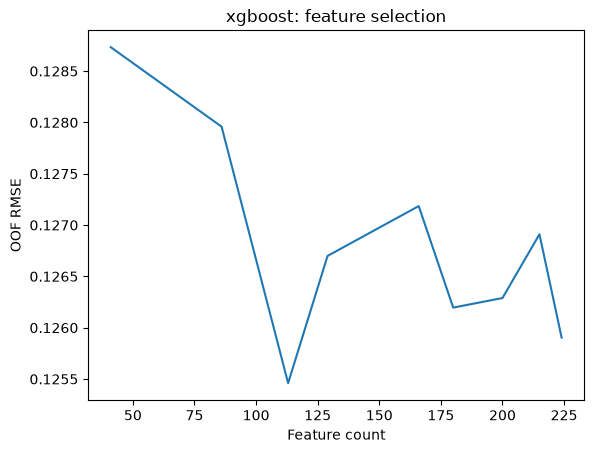

In [124]:
xgboost_fs_results = run_feature_selection(
    X=X_train,
    y=y_train,
    cv_folds=xgboost_results['cv_folds'],
    importance=xgboost_shap['importance'],
    search_results=xgboost_results['best_results'],
    model_name="xgboost",
    model_configs=xgboost_pipeline,
    model_run_id=xgboost_results['run_id'],
    logger=logger
)

if xgboost_fs_results["best_oof_score"] < xgboost_results['best_results']['best_oof_score']:
    ModelSaver.save_ensemble(xgboost_fs_results['best_ensemble'],"xgboost", save_fs=xgboost_fs_results['best_results']['best_cols'])
else:
    ModelSaver.save_ensemble(xgboost_results['best_ensemble'],"xgboost")

## Stacking Ridge

In [34]:
ridge_params = {
        "parameters": {
            "model__alpha": np.float64(0.11144234247204798),
            "model__solver": "saga",
            "model__max_iter": 1000,
            "model__random_state": Config.seed,
        },
        "fit_param": {#'feature_transform__selected_columns':
            # [
            #     "Alley",
            #     "BldgType",
            #     "Condition1",
            #     "Exterior1st",
            #     "Exterior2nd",
            #     "Fence",
            #     "Foundation",
            #     "GarageType",
            #     "Heating",
            #     "HouseStyle",
            #     "LandContour",
            #     "LotConfig",
            #     "MSSubClass",
            #     "MSZoning",
            #     "Neighborhood",
            #     "PavedDrive",
            #     "SaleCondition",
            #     "SaleType",
            #     "1stFlrSF",
            #     "1stFlrSF_log",
            #     "2ndFlrSF",
            #     "2ndFlrSF_log",
            #     "Age",
            #     "Age_from_Remod",
            #     "BsmtExposure",
            #     "BsmtFinSF1",
            #     "BsmtFinSF1_log",
            #     "BsmtFinType1*BsmtFinSF1*BsmtQual",
            #     "BsmtQual",
            #     "CentralAir",
            #     "ExterCond",
            #     "ExterQual*ExterCond",
            #     "FullBath",
            #     "Functional",
            #     "GarageArea",
            #     "GarageCars",
            #     "GrLivArea",
            #     "GrLivArea_log",
            #     "HalfBath",
            #     "HeatingQC",
            #     "KitchenAbvGr",
            #     "KitchenQual",
            #     "LotArea_log",
            #     "LotFrontage_log",
            #     "MasVnrArea",
            #     "OpenPorchSF_log",
            #     "OverallBath",
            #     "OverallCond",
            #     "OverallQual",
            #     "OverallQual*OverallCond",
            #     "Overall_Fireplaces",
            #     "ScreenPorch",
            #     "TotRmsAbvGrd",
            #     "TotalBsmtSF",
            #     "TotalSqFeet",
            #     "TotalSqFeet_log",
            #     "WoodDeckSF"
            # ]
        }
    }

xgb_params = {
        "parameters": {
            "model__device": "cuda",
            "model__booster": "gbtree",
            "model__tree_method": "hist",
            "model__n_estimators": 1000,
            "model__learning_rate":np.float64(0.013190161120540767),
            "model__max_depth": 6,
            "model__min_child_weight": 0.03794613934217169,
            "model__n_jobs": 1,
            "model__subsample": 0.4,
            "model__colsample_bytree": 0.75,
            "model__reg_alpha": 0.0193336968922133,
            "model__reg_lambda": 0.032333649917330995,
            "model__gamma": 0.017362357647552687,
            "model__objective": "reg:squarederror",
            "model__eval_metric": "rmse",
            "model__random_state": Config.seed,
        },
        "fit_param": {#'feature_transform__selected_columns':
            # [
            #     "Condition1",
            #     "Exterior1st",
            #     "Foundation",
            #     "GarageType",
            #     "MSSubClass",
            #     "MSZoning",
            #     "Neighborhood",
            #     "SaleCondition",
            #     "2ndFlrSF",
            #     "Age",
            #     "Age_from_Remod",
            #     "BsmtExposure",
            #     "BsmtFinSF1",
            #     "BsmtFinType1*BsmtFinSF1*BsmtQual",
            #     "BsmtQual",
            #     "BsmtUnfSF",
            #     "CentralAir",
            #     "Functional",
            #     "GarageArea",
            #     "GarageCars",
            #     "GarageFinish",
            #     "GrLivArea",
            #     "GrLivArea_log",
            #     "KitchenQual",
            #     "LotArea",
            #     "OpenPorchSF",
            #     "OverallBath",
            #     "OverallCond",
            #     "OverallQual",
            #     "OverallQual*OverallCond",
            #     "Overall_Fireplaces",
            #     "TotalSqFeet",
            #     "TotalSqFeet_log"
            # ]
        }
    }

rf_params = {
        "parameters": {
            "model__n_estimators": 1000,
            "model__max_depth": 14,
            "model__criterion": "squared_error",
            "model__n_jobs": -1,
            "model__min_samples_split": 10,
            "model__min_samples_leaf": 5,
            "model__max_leaf_nodes": 100,
            "model__min_impurity_decrease": 0,
            "model__max_features": None,
            "model__bootstrap": True,
            "model__max_samples": 0.8,
            "model__oob_score": True,
            "model__random_state": Config.seed,
        },
        "fit_param": {#'feature_transform__selected_columns':
                    # [
                    #     "GarageType",
                    #     "LotShape",
                    #     "MSSubClass",
                    #     "MSZoning",
                    #     "Neighborhood",
                    #     "2ndFlrSF",
                    #     "2ndFlrSF_log",
                    #     "Age",
                    #     "Age_from_Remod",
                    #     "BsmtExposure",
                    #     "BsmtFinSF1",
                    #     "BsmtFinSF1_log",
                    #     "BsmtFinType1*BsmtFinSF1*BsmtQual",
                    #     "BsmtQual",
                    #     "BsmtUnfSF",
                    #     "BsmtUnfSF_log",
                    #     "CentralAir",
                    #     "GarageArea",
                    #     "GarageArea_log",
                    #     "GarageCars",
                    #     "GarageFinish",
                    #     "GrLivArea",
                    #     "GrLivArea_log",
                    #     "KitchenQual",
                    #     "LotArea",
                    #     "LotArea_log",
                    #     "OverallBath",
                    #     "OverallCond",
                    #     "OverallQual",
                    #     "OverallQual*OverallCond",
                    #     "Overall_Fireplaces",
                    #     "TotalSqFeet",
                    #     "TotalSqFeet_log"
                    # ]
                }
         }

lgbm_params = {
        "parameters": {
            "model__device": "cpu",
            "model__boosting_type": "gbdt",
            "model__n_estimators": 2000,
            "model__learning_rate": 0.098,
            "model__max_depth": 4,
            "model__subsample": 0.4,
            "model__colsample_bytree": 0.8,
            "model__reg_alpha": 0.008,
            "model__reg_lambda": 0.04000000000000001,
            "model__objective": "regression",
            "model__metric": "rmse",
            "model__min_child_samples": 40,
            "model__min_child_weight": 1,
            "model__min_split_gain": 0.0005,
            "model__n_jobs": -1,
            "model__random_state": Config.seed,
            "model__verbosity": -1,
            "model__early_stopping_round": 30,
        },
        "fit_param": {#'feature_transform__selected_columns':
            # [
            #     "1stFlrSF",
            #     "1stFlrSF_log",
            #     "2ndFlrSF",
            #     "2ndFlrSF_log",
            #     "3SsnPorch",
            #     "Age",
            #     "Age_from_Remod",
            #     "Alley",
            #     "BedroomAbvGr",
            #     "BldgType",
            #     "BsmtExposure",
            #     "BsmtFin",
            #     "BsmtFinSF1",
            #     "BsmtFinSF1_log",
            #     "BsmtFinType1*BsmtFinSF1*BsmtQual",
            #     "BsmtFinType2*BsmtFinSF2*BsmtQual",
            #     "BsmtHalfBath",
            #     "BsmtQual",
            #     "BsmtUnfSF",
            #     "BsmtUnfSF_log",
            #     "CentralAir",
            #     "Condition1",
            #     "Condition2",
            #     "Electrical",
            #     "EnclosedPorch",
            #     "ExterCond",
            #     "ExterQual*ExterCond",
            #     "Exterior1st",
            #     "Exterior2nd",
            #     "Fence",
            #     "Foundation",
            #     "FullBath",
            #     "Functional",
            #     "GarageArea",
            #     "GarageArea_log",
            #     "GarageCars",
            #     "GarageFinish",
            #     "GarageType",
            #     "GrLivArea",
            #     "GrLivArea_log",
            #     "HalfBath",
            #     "Heating",
            #     "HeatingQC",
            #     "HouseStyle",
            #     "KitchenAbvGr",
            #     "KitchenQual",
            #     "LandContour",
            #     "LandSlope",
            #     "LotArea",
            #     "LotArea_log",
            #     "LotConfig",
            #     "LotFrontage",
            #     "LotFrontage_log",
            #     "LotShape",
            #     "LowQualFin",
            #     "MSSubClass",
            #     "MSZoning",
            #     "MasVnrArea",
            #     "MasVnrArea_log",
            #     "MoSold",
            #     "Neighborhood",
            #     "OpenPorch",
            #     "OpenPorchSF",
            #     "OpenPorchSF_log",
            #     "OverallBath",
            #     "OverallCond",
            #     "OverallQual",
            #     "OverallQual*OverallCond",
            #     "Overall_Fireplaces",
            #     "PavedDrive",
            #     "RoofStyle",
            #     "SaleCondition",
            #     "ScreenPorch",
            #     "TotRmsAbvGrd",
            #     "TotalBsmtSF",
            #     "TotalBsmtSF_log",
            #     "TotalSqFeet",
            #     "TotalSqFeet_log",
            #     "WoodDeckSF",
            #     "WoodDeckSF_log",
            #     "YrSold"
            # ]
        }
    }

cat_params = {
        "parameters": {
            "model__boosting_type": "Plain",
            "model__iterations": 1000,
            "model__learning_rate": 0.05211448378065621,
            "model__depth": 4,
            "model__bootstrap_type": "Bernoulli",
            "model__thread_count": -1,
            "model__l2_leaf_reg": 0.01727277227745447,
            "model__rsm": 1.0,
            "model__subsample": 0.8,
            "model__border_count": 256,
            "model__min_data_in_leaf": 50,
            "model__max_ctr_complexity": 2,
            "model__one_hot_max_size": 6,
            "model__eval_metric": "RMSE",
            "model__loss_function": "RMSE",
            "model__random_strength": 1.7444045228543141,
            "model__verbose": False,
            "model__random_seed": Config.seed,
            "model__early_stopping_rounds": 50,
        },
        "fit_param": {
            "model__cat_features": FeatureTransformer.cat_cols
        }
    }

dnn_params = {
        "parameters": {
            "model__cat_cols": FeatureTransformer.cat_cols,
            "model__num_cols": FeatureTransformer.num_cols,
            "model__epochs": 1000,
            "model__device": Config.device,
            "model__emb_dim": 12,
            "model__inner_n": 512,
            "model__drop_n": 0.1,
            "model__n_layers": 1,
            "model__use_batchnorm": True,
            "model__loss_reg": RMSELoss,
            "model__l1_lambda": 0.003433628682365358,
            "model__optim": torch.optim.Adam,
            "model__optim_lr": 0.08686979995821902,
            "model__scheduler": torch.optim.lr_scheduler.ReduceLROnPlateau,
            "model__lr_scheduler": True,
            "model__factor": 0.08066252499544253,
            "model__patience": 15,
            "model__threshold": 0.01,
            "model__min_lr": 1e-10,
            "model__early_stopping_patience": 45,
            "model__early_stopping_threshold": 0.001,
            "model__batch_size": 64,
            "model__saving_threshold": 0.001,
            "model__save_path": "checkpoints",
        },
        "fit_param": {
            "model__callbacks": [
                CheckpointManager(),
                EarlyStopping()
            ],
            # 'feature_transform__selected_columns':{}
            # [
            #     "1stFlrSF_log",
            #     "2ndFlrSF",
            #     "Age",
            #     "Age_from_Remod",
            #     "BsmtExposure",
            #     "BsmtFinSF1",
            #     "BsmtFinSF1_log",
            #     "BsmtFinType1*BsmtFinSF1*BsmtQual",
            #     "BsmtHalfBath",
            #     "BsmtQual",
            #     "CentralAir",
            #     "Condition1",
            #     "ExterCond",
            #     "Exterior1st",
            #     "Exterior2nd",
            #     "Fence",
            #     "Foundation",
            #     "FullBath",
            #     "Functional",
            #     "GarageArea",
            #     "GarageArea_log",
            #     "GarageCars",
            #     "GarageFinish",
            #     "GarageType",
            #     "GrLivArea",
            #     "GrLivArea_log",
            #     "HalfBath",
            #     "HeatingQC",
            #     "HouseStyle",
            #     "KitchenAbvGr",
            #     "KitchenQual",
            #     "LotArea_log",
            #     "LotConfig",
            #     "LotFrontage",
            #     "LotShape",
            #     "MSSubClass",
            #     "MSZoning",
            #     "MasVnrArea",
            #     "Neighborhood",
            #     "OpenPorchSF",
            #     "OpenPorchSF_log",
            #     "OverallBath",
            #     "OverallCond",
            #     "OverallQual",
            #     "OverallQual*OverallCond",
            #     "Overall_Fireplaces",
            #     "PoolOverall",
            #     "RoofStyle",
            #     "SaleCondition",
            #     "SaleType",
            #     "ScreenPorch",
            #     "TotRmsAbvGrd",
            #     "TotalBsmtSF",
            #     "TotalSqFeet",
            #     "TotalSqFeet_log",
            #     "WoodDeckSF",
            #     "WoodDeckSF_log"
            # ]
        }
    }

# ridge_meta_params = {
#         "parameters": {
#             "model__alpha": np.float64(0.11144234247204798),
#             "model__solver": "saga",
#             "model__max_iter": 1000,
#             "model__random_state": Config.seed,
#         },
#         "fit_param": {}
#     }
#------------------------------------------------------------------------------------------------------------------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=Config.seed)
cv_folds = list(kf.split(X_train, y_train))


start_val = 0.001
stop_val = 10

meta_params = np.logspace(np.log10(start_val), np.log10(stop_val), num=1) #np.linspace(0.001,10,100)
best_oof = +float('inf')
best_alpha = 0
best_meta = None

for a in meta_params:
    ridge_meta_params = {
            "parameters": {
                "model__alpha": a,
                "model__solver": "saga",
                "model__max_iter": 1000,
                "model__random_state": Config.seed,
            },
            "fit_param": {}
        }

    meta_ridge = MyStackingRidge(groups = {},meta_cols=["xgb", "catboost", "lightgbm", "rf", "dnn", "ridgebase"], return_mean=True) #,'{"avg_boost": ["xgb", "catboost", "lightgbm"]}
    meta_ridge.fit_sub_models(X_train, y_train,
            rf_params, dnn_params, cat_params,
            lgbm_params, xgb_params, ridge_params,
            cv_folds, Config.seed)

    meta_res = meta_ridge.fit(X_train, y_train, ridge_meta_params, cv_folds, Config.seed)

    if meta_res['oof_rmse'] < best_oof:
        best_oof = meta_res['oof_rmse']
        best_alpha = a
        best_meta = meta_ridge

    print(f"Скор текущей итерации {meta_res['oof_rmse']}\n")
    
print(f"Лучший OFF {best_oof}, лучший альфа {best_alpha}")
ModelSaver.save_ensemble([best_meta],'meta_ridge')

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Обучился xgb


Training:   0%|          | 0/5 [00:00<?, ?it/s]

Обучился catboost


Training:   0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\user\3D Objects\code 2\Mento

... (13 outputs left out)

Обучение остановлено на эпохе 170
Обучился dnn


Training:   0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users\user\3D Objects\code 2\Mentor_python\Block 2\Final_prodject\House_prices_kaggle\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
c:\Users

Обучился ridgebase
Скор текущей итерации 0.12323812429296703

Лучший OFF 0.12323812429296703, лучший альфа 0.001


- all models = np.float64(0.11496592354180112)
- all models + boostig avg = np.float64(0.11496424607701092)
- rf,dnn,ridge + boostig avg = np.float64(0.1143016989436201)

In [25]:
print(f"Лучший OFF {best_oof}, лучший альфа {best_alpha}")

Лучший OFF 0.1216821561939151, лучший альфа 0.001


## Hold-out results

In [35]:
saved_models = ModelSaver.upload_saved_models(Config.path_to_save_models)


Model: catboost
Найдены модели
Selected features: all

Model: DNN
Найдены модели
Selected features: 57

Model: lasso
Найдены модели
Selected features: all

Model: lightgbm
Найдены модели
Selected features: 81

Model: meta_ridge
Найдены модели
Selected features: all

Model: random_forest
Найдены модели
Selected features: 33

Model: ridge
Найдены модели
Selected features: 57

Model: xgboost
Найдены модели
Selected features: 33


In [36]:
Predictor.run_test(saved_models,X_holdout,y_holdout)
print()

        model  holdout_log_rmse
        lasso           0.11919
        ridge           0.12034
   meta_ridge           0.12431
      xgboost           0.12497
     catboost           0.12506
          DNN           0.13193
     lightgbm           0.13274
random_forest           0.14943

